# 07 · La regla correcta y las preguntas pendientes

## Propósito

Durante los seis primeros cuadernos quedaron varias preguntas abiertas. Algunas se registraron en las síntesis o en las limitaciones, y otras surgieron al revisar los resultados. Este cuaderno las reúne y las responde con los datos disponibles, o explica por qué SPIDER no permite resolverlas. Es el primero de los cuadernos de cierre del proyecto, ya que cada cierto número de cuadernos se hará un balance similar de las preguntas acumuladas.

La pregunta principal era por qué `compute-Cobb-angle.py`, al ejecutarse sobre las máscaras de SPIDER, selecciona caras de disco distintas de las descritas en el artículo. En su segunda respuesta al issue, Jasper van der Graaf explicó que el algoritmo se desarrolló con las salidas de SPIDER-Baseline-IIS, cuyas etiquetas aumentan de arriba hacia abajo, mientras que SPIDER las numera de abajo hacia arriba. Como la lógica que empareja las caras depende de esa numeración, el orden de las etiquetas cambia el resultado. También confirmó que el segmentador se desarrolló con las particiones de entrenamiento y validación de SPIDER.

Este cuaderno no propone un método nuevo. Su objetivo es comprobar la explicación de los autores, cuantificar cuánto cambia el ángulo al aplicar el emparejamiento previsto y revisar, una por una, las preguntas que quedaron abiertas.

## Preguntas que responde

| Cuaderno de origen | Pregunta | Sección |
|---|---|---|
| 01 | ¿Coinciden los conteos por hospital con la Tabla 1 del artículo de SPIDER? ¿Se puede saber a qué hospital pertenece cada estudio? | Los centros de SPIDER |
| 02 | ¿Cuánto cambia el ángulo según el número de niveles que entran en la máscara? | Cuántos niveles entran en la máscara |
| 03 | ¿Por qué el script elige la cara inferior del disco 201? ¿Cuál de las variantes se acerca a la medida correcta? | La regla correcta · Evitar el disco 201 |
| 03 | ¿$\arctan(n_x/n_z)$ o $\arcsin(n_x)$? | La fórmula de la inclinación |
| 03 | ¿Son confiables las caras del disco más craneal y cuánto cambia el ángulo sin ellas? | El disco más craneal |
| 04 | ¿Se mantienen las cifras del grosor de corte con la regla del artículo? | El grosor de corte con la regla correcta |
| 05 | ¿Hay diferencia entre las series de entrenamiento y las de validación? | Entrenamiento frente a validación |
| 05 y 06 | ¿Por qué el extremo caudal del estudio 65 cambia tanto según la máscara o la superficie que se mida? ¿Se repite en otras columnas? | La dirección de la inclinación |
| 06 | ¿Cuánto cambian los resultados si la distancia de contacto se fija en 2 o 4 mm? | La distancia de contacto de los platillos |

Las preguntas que no se pueden responder con SPIDER se reúnen al final, antes de la síntesis.

## Alcance

El análisis es técnico y descriptivo. Se basa en las máscaras manuales de SPIDER v4 y en los resultados de los cuadernos 01 a 06. Al igual que en los análisis anteriores, se consideran las 340 máscaras únicas, excepto en las comparaciones con segmentaciones automáticas, que son diferentes para cada serie aunque una misma máscara manual pueda corresponder a más de una serie.

La explicación sobre la dirección de las etiquetas proviene de la respuesta de uno de los autores en el issue, no de una publicación revisada por pares ni del código. Aquí se comprueba que es coherente con los planos, pero no se vuelve a correr el script sobre máscaras renumeradas. Además, que una regla coincida con el método descrito no demuestra que sea más exacta frente a una medición clínica, porque SPIDER no incluye ángulos de Cobb medidos por especialistas. Este trabajo no constituye una validación clínica ni está destinado al diagnóstico de escoliosis.

## Fuentes

- **Respuesta de los autores.** Jasper van der Graaf en [DIAGNijmegen/cobb-angle-algorithm#1](https://github.com/DIAGNijmegen/cobb-angle-algorithm/issues/1), segunda respuesta (28-oct-2026). Comunicación de un autor, no publicada.
- **Tabla 1 del artículo de SPIDER.** van der Graaf *et al.*, *Scientific Data* 11, 264 (2024), [doi:10.1038/s41597-024-03090-w](https://doi.org/10.1038/s41597-024-03090-w). Los valores se transcribieron de la versión publicada en [PMC10908819](https://pmc.ncbi.nlm.nih.gov/articles/PMC10908819/) y [arXiv:2306.12217](https://arxiv.org/abs/2306.12217).
- **Inventario de SPIDER.** `inventario_series.csv` del cuaderno 01.
- **Planos de las caras de disco y variantes.** `planos_por_disco.csv` y `angulos_variantes.csv` del cuaderno 03, generados con [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`.
- **Experimento de grosor.** `planos_engrosamiento.csv` y `bland_altman_comparaciones.csv` del cuaderno 04.
- **Segmentación automática.** `comparacion_por_serie.csv`, `planos_por_disco_iis.csv` y `planos_por_disco_tss.csv` del cuaderno 05.
- **Platillos vertebrales.** `cobb_por_serie.csv` y `platillos_por_vertebra.csv` del cuaderno 06, y sus funciones, copiadas sin cambios en el método.
- **Dependencia.** [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`, para reorientar y remuestrear las máscaras igual que el script.
- **Método publicado.** van der Graaf *et al.*, *European Radiology* (2024), [artículo completo](https://pmc.ncbi.nlm.nih.gov/articles/PMC11364572/).
- **Datos.** [SPIDER v4](https://doi.org/10.5281/zenodo.10159290), licencia CC BY 4.0.

## Antes de ejecutar: datos necesarios

Este cuaderno no vuelve a ejecutar el script ni los segmentadores. Utiliza los resultados de los cuadernos 01 a 06 y, para analizar el disco más craneal y la distancia de contacto, las máscaras de SPIDER. Los siguientes archivos deben estar disponibles en Google Drive.

| Archivo | Ruta en Google Drive | Obligatorio |
|---|---|---|
| `masks.zip` | `MyDrive/PRL/content/datos/spider/masks/masks.zip` | Sí |
| `inventario_series.csv` | `MyDrive/PRL/salidas/resultados_semana1/01_INVENTARIO_SPIDER/inventario_series.csv` | Sí |
| `angulos_variantes.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/angulos_variantes.csv` | Sí |
| `planos_por_disco.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/planos_por_disco.csv` | Sí |
| `planos_engrosamiento.csv` | `MyDrive/PRL/salidas/resultados_semana2/04_robustez_grosor_de_corte/planos_engrosamiento.csv` | Sí |
| `bland_altman_comparaciones.csv` | `MyDrive/PRL/salidas/resultados_semana2/04_robustez_grosor_de_corte/bland_altman_comparaciones.csv` | Sí |
| `comparacion_por_serie.csv` | `MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica/comparacion_por_serie.csv` | Sí |
| `planos_por_disco_iis.csv` | `MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica/planos_por_disco_iis.csv` | Sí |
| `planos_por_disco_tss.csv` | `MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica/planos_por_disco_tss.csv` | Sí |
| `cobb_por_serie.csv` | `MyDrive/PRL/salidas/resultados_semana3/06_cobb_por_platillos/cobb_por_serie.csv` | Sí |
| `platillos_por_vertebra.csv` | `MyDrive/PRL/salidas/resultados_semana3/06_cobb_por_platillos/platillos_por_vertebra.csv` | Sí |
| Máscaras de TotalSpineSeg | `MyDrive/PRL/content/datos/AutoSegments/tss/convencion_spider/` (447 archivos `.mha`) | Sí, para la fórmula |
| Máscaras de SPIDER-Baseline-IIS | `MyDrive/PRL/content/datos/AutoSegments/iis/convencion_spider/` (447 archivos `.mha`) | Sí, para la fórmula |

Los resultados se guardan en la siguiente carpeta.

`MyDrive/PRL/salidas/resultados_semana4/07_regla_del_articulo_y_preguntas_pendientes/`

No se necesita GPU, aunque el cuaderno es extenso. La revisión del campo de visión tarda unos cinco minutos para las 340 máscaras, y la prueba de la fórmula requiere unos dos minutos con discos sintéticos y cerca de una hora con 1000 discos reales. La proyección de los discos en las máscaras manuales y automáticas tarda algo más de una hora, y el recálculo de los platillos con tres distancias de contacto, unos 20 minutos. Las celdas más largas guardan el avance en Drive. Si Colab se interrumpe, basta con volver a ejecutar la configuración y las funciones para continuar desde el último punto guardado. Las demás celdas se ejecutan en segundos o pocos minutos.

In [ ]:
# 1. Dependencias: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 2. Configuración
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
ZIP_MASCARAS = DIR_PRL / "content" / "datos" / "spider" / "masks" / "masks.zip"
SALIDAS = DIR_PRL / "salidas"                                                     # todo lo anterior es solo lectura
CSV_INVENTARIO_01 = SALIDAS / "resultados_semana1" / "01_INVENTARIO_SPIDER" / "inventario_series.csv"
DIR_03 = SALIDAS / "resultados_semana2" / "03_disco_caudal_y_variantes"
CSV_VARIANTES_03 = DIR_03 / "angulos_variantes.csv"
CSV_PLANOS_03 = DIR_03 / "planos_por_disco.csv"
DIR_04 = SALIDAS / "resultados_semana2" / "04_robustez_grosor_de_corte"
CSV_PLANOS_04 = DIR_04 / "planos_engrosamiento.csv"
CSV_COMPARACIONES_04 = DIR_04 / "bland_altman_comparaciones.csv"
DIR_05 = SALIDAS / "resultados_semana3" / "05_segmentacion_automatica"
CSV_COMPARACION_05 = DIR_05 / "comparacion_por_serie.csv"
CSV_PLANOS_IIS_05 = DIR_05 / "planos_por_disco_iis.csv"
CSV_PLANOS_TSS_05 = DIR_05 / "planos_por_disco_tss.csv"
DIR_06 = SALIDAS / "resultados_semana3" / "06_cobb_por_platillos"
CSV_COBB_06 = DIR_06 / "cobb_por_serie.csv"
CSV_PLATILLOS_06 = DIR_06 / "platillos_por_vertebra.csv"
DIR_SALIDA = SALIDAS / "resultados_semana4" / "07_regla_del_articulo_y_preguntas_pendientes"
DIR_LOCAL = Path("/content/mascaras_unicas")       # copia local: leer de Drive en cada serie es lento

COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"   # el que produjo los planos de los cuadernos 03, 04 y 05
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"   # descarga verificada contra Zenodo el 2-oct-2026
N_ESPERADO = 447                                      # series de SPIDER según el cuaderno 01
N_UNICAS = 340                                        # máscaras distintas según el cuaderno 03
B_BOOTSTRAP, SEMILLA = 2000, 2026                     # igual que en los cuadernos 05 y 06

ENTRADAS = (ZIP_MASCARAS, CSV_INVENTARIO_01, CSV_VARIANTES_03, CSV_PLANOS_03, CSV_PLANOS_04, CSV_COMPARACIONES_04,
            CSV_COMPARACION_05, CSV_PLANOS_IIS_05, CSV_PLANOS_TSS_05, CSV_COBB_06, CSV_PLATILLOS_06)
for archivo in ENTRADAS:
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de datos necesarios"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

def leer(ruta):
    return pd.read_csv(ruta, dtype={"serie": str})

inventario = leer(CSV_INVENTARIO_01)
variantes = leer(CSV_VARIANTES_03)
planos_disco = leer(CSV_PLANOS_03).drop_duplicates(["serie", "disco", "cara"], keep="last")
planos_04 = leer(CSV_PLANOS_04)
comparaciones_04 = pd.read_csv(CSV_COMPARACIONES_04)
comparacion_05 = leer(CSV_COMPARACION_05)
planos_iis = leer(CSV_PLANOS_IIS_05)
planos_tss = leer(CSV_PLANOS_TSS_05)
cobb_06 = leer(CSV_COBB_06).set_index("serie")
platillos_06 = leer(CSV_PLATILLOS_06)

unicas = sorted(variantes.loc[variantes["mascara_unica"], "serie"])
assert len(variantes) == N_ESPERADO, f"angulos_variantes.csv debería tener {N_ESPERADO} series"
assert len(unicas) == N_UNICAS, f"Se esperaban {N_UNICAS} máscaras únicas y hay {len(unicas)}"
assert set(cobb_06.index) == set(unicas), "cobb_por_serie.csv del cuaderno 06 no tiene las mismas máscaras únicas"
assert planos_disco["serie"].nunique() == N_ESPERADO, "planos_por_disco.csv debería tener las 447 series"
estudio_de = variantes.set_index("serie")["estudio"]
print(f"Máscaras únicas: {len(unicas)} | caras de disco del cuaderno 03: {len(planos_disco)} | "
      f"filas del cuaderno 05: {len(comparacion_05)} | platillos del cuaderno 06: {len(platillos_06)}")
print("Salida:", DIR_SALIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Máscaras únicas: 340 | caras de disco del cuaderno 03: 6294 | filas del cuaderno 05: 894 | platillos del cuaderno 06: 4786
Salida: /content/drive/MyDrive/PRL/salidas/resultados_semana4/07_regla_del_articulo_y_preguntas_pendientes


In [ ]:
# 3. Funciones comunes: las dos reglas de emparejamiento y el resumen de acuerdo
def tabla_de_caras(caras, columna="angulo_coronal_script"):
    "Una fila por disco (etiqueta de SPIDER) con la inclinación de su cara inferior y de su cara superior."
    return caras.pivot(index="disco", columns="cara", values=columna)

def maximo_entre_discos(tabla, cara_primero, cara_segundo, orden="caudal_a_craneal", excluir=()):
    """Recorre los discos en el orden indicado y, para cada par (primero, segundo) con el primero antes que el segundo,
    compara la cara `cara_primero` del primero con la cara `cara_segundo` del segundo. Devuelve el máximo y el par
    (primero, segundo). excluir: caras (disco, cara) que no pueden usarse."""
    discos = sorted(tabla.index, reverse=(orden == "craneal_a_caudal"))
    mejor = (np.nan, np.nan, np.nan)
    for i, a in enumerate(discos):
        for b in discos[i + 1:]:
            if (a, cara_primero) in excluir or (b, cara_segundo) in excluir:
                continue
            v = abs(tabla.loc[a, cara_primero] - tabla.loc[b, cara_segundo])
            if np.isnan(mejor[0]) or v > mejor[0]:
                mejor = (float(v), int(a), int(b))
    return mejor

def regla_script(tabla, **kw):
    "Como corre el script sobre SPIDER: cara inferior del disco de abajo contra cara superior del de arriba."
    return maximo_entre_discos(tabla, "inferior", "superior", "caudal_a_craneal", **kw)

def regla_articulo(tabla, **kw):
    "Como la describe el artículo: cara superior del disco de abajo contra cara inferior del de arriba."
    return maximo_entre_discos(tabla, "superior", "inferior", "caudal_a_craneal", **kw)

def bland_altman(df, col):
    "Sesgo con IC por bootstrap de estudios completos, límites de acuerdo y resumen de la diferencia absoluta."
    d = df[col].dropna()
    if len(d) < 3:
        return {"n": len(d)}
    rng = np.random.default_rng(SEMILLA)
    grupos = [g.values for _, g in df.loc[d.index].groupby("estudio")[col]]
    sesgos = [np.mean(np.concatenate([grupos[k] for k in rng.integers(0, len(grupos), len(grupos))]))
              for _ in range(B_BOOTSTRAP)]           # se remuestrean estudios completos, no series
    sesgo, de = d.mean(), d.std(ddof=1)
    return {"n": len(d), "estudios": len(grupos), "sesgo": sesgo,
            "ic95_sesgo": f"{np.percentile(sesgos, 2.5):.2f} a {np.percentile(sesgos, 97.5):.2f}",
            "lim_inf": sesgo - 1.96 * de, "lim_sup": sesgo + 1.96 * de,
            "mediana_abs": d.abs().median(), "p90_abs": d.abs().quantile(0.9), "max_abs": d.abs().max()}

NOMBRES = {"iis": "SPIDER-Baseline-IIS", "tss": "TotalSpineSeg"}

def ejes_limpios(ax):
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

print("Funciones listas.")

Funciones listas.


## Cuaderno 01 · Los centros de SPIDER

`overview.csv` no incluye una columna que identifique el hospital. Por eso, en el cuaderno 01 se construyó un indicador aproximado, en el que los estudios con una serie T2 SPACE se asignaron al centro universitario (UMC), según el artículo, y los demás se agruparon por escáner. Quedaba pendiente contrastar esos conteos con la Tabla 1 del artículo de SPIDER, que presenta para cada hospital el número de estudios, las series T1, T2 y T2 SPACE, y el porcentaje de mujeres.

La celda 4 compara los conteos y va un paso más allá, porque evalúa todas las asignaciones posibles de los grupos de escáner a los tres hospitales sin T2 SPACE (RH1, RH2 y OH) para identificar cuáles reproducen exactamente la Tabla 1. Si solo existe una asignación compatible, los datos del escáner permiten inferir el hospital de cada estudio. El porcentaje de mujeres no se utiliza para encontrar la asignación, sino como comprobación posterior.

In [ ]:
# 4. Grupos de escáner frente a la Tabla 1 del artículo de SPIDER (van der Graaf et al., Sci Data 2024)
import itertools
TABLA_1 = pd.DataFrame({            # estudios, series T1, T2 y T2 SPACE, y % de mujeres, tal como los publica la tabla
    "estudios": {"UMC": 41, "RH1": 43, "RH2": 44, "OH": 90},
    "t1": {"UMC": 39, "RH1": 43, "RH2": 24, "OH": 90},
    "t2": {"UMC": 39, "RH1": 37, "RH2": 44, "OH": 90},
    "t2_SPACE": {"UMC": 41, "RH1": 0, "RH2": 0, "OH": 0},
    "mujeres_pct": {"UMC": 55, "RH1": 58, "RH2": 59, "OH": 68}})
CONTEOS = ["estudios", "t1", "t2", "t2_SPACE"]

por_estudio = inventario.drop_duplicates("estudio").set_index("estudio")
grupos = (inventario.groupby("centro_proxy")
          .agg(estudios=("estudio", "nunique"),
               **{s: ("secuencia", lambda x, s=s: int((x == s).sum())) for s in ("t1", "t2", "t2_SPACE")}))
grupos["mujeres"] = por_estudio.groupby("centro_proxy")["sexo"].apply(lambda x: int((x == "F").sum()))
display(grupos)

umc = [g for g in grupos.index if g.startswith("UMC")]
otros = [g for g in grupos.index if g not in umc]
assert grupos.loc[umc, CONTEOS].sum().tolist() == TABLA_1.loc["UMC", CONTEOS].tolist(), "El grupo UMC no coincide con la Tabla 1"
soluciones = []
for asignacion in itertools.product(["RH1", "RH2", "OH"], repeat=len(otros)):
    reparto = dict(zip(otros, asignacion))
    if all(grupos.loc[[g for g, h in reparto.items() if h == hosp], CONTEOS].sum().tolist() == TABLA_1.loc[hosp, CONTEOS].tolist()
           for hosp in ("RH1", "RH2", "OH")):
        soluciones.append(reparto)
print(f"Repartos de los {len(otros)} grupos de escáner compatibles con los conteos de la Tabla 1: {len(soluciones)}")

if len(soluciones) == 1:
    hospital_de = {**{g: "UMC" for g in umc}, **soluciones[0]}
    comparacion_centros = TABLA_1.copy()
    for hosp in TABLA_1.index:
        sel = [g for g, h in hospital_de.items() if h == hosp]
        comparacion_centros.loc[hosp, "grupos_de_escaner"] = " + ".join(g.replace("otro: ", "") for g in sel)
        comparacion_centros.loc[hosp, "mujeres_inventario"] = int(grupos.loc[sel, "mujeres"].sum())
        comparacion_centros.loc[hosp, "mujeres_pct_inventario"] = round(100 * grupos.loc[sel, "mujeres"].sum()
                                                                         / grupos.loc[sel, "estudios"].sum(), 1)
    comparacion_centros["diferencia_en_pacientes"] = (comparacion_centros["mujeres_inventario"]
                                                      - comparacion_centros["mujeres_pct"] / 100 * comparacion_centros["estudios"]).round(1)
    comparacion_centros.to_csv(DIR_SALIDA / "centros_frente_a_tabla1.csv")
    series_por_hospital = inventario[["serie", "estudio", "centro_proxy"]].assign(
        hospital_inferido=inventario["centro_proxy"].map(hospital_de))
    series_por_hospital.to_csv(DIR_SALIDA / "hospital_inferido_por_serie.csv", index=False)
    display(comparacion_centros)
else:
    print("El reparto no es único; no se asigna hospital a los estudios.")
    for s in soluciones:
        print(s)

,estudios,t1,t2,t2_SPACE,mujeres
centro_proxy,,,,,
UMC (inferido por SPACE),41,39,39,41,23
otro: Philips Healthcare | Ingenia | 3.0 T,90,90,90,0,62
otro: Philips Medical Systems | Ingenia | 1.5 T,18,12,18,0,12
otro: Philips Medical Systems | Ingenia | 3.0 T,1,0,1,0,1
otro: SIEMENS | Aera | 1.5 T,17,17,16,0,8
otro: SIEMENS | Avanto | 1.5 T,1,1,1,0,0
otro: SIEMENS | Avanto_fit | 1.5 T,24,11,24,0,14
otro: SIEMENS | Skyra_fit | 3.0 T,5,5,5,0,5
otro: SIEMENS | SymphonyTim | 1.5 T,21,21,16,0,11


Repartos de los 8 grupos de escáner compatibles con los conteos de la Tabla 1: 1


,estudios,t1,t2,t2_SPACE,mujeres_pct,grupos_de_escaner,mujeres_inventario,mujeres_pct_inventario,diferencia_en_pacientes
UMC,41,39,39,41,55,UMC (inferido por SPACE),23.0,56.1,0.4
RH1,43,43,37,0,58,SIEMENS | Aera | 1.5 T + SIEMENS | Skyra_fit |...,24.0,55.8,-0.9
RH2,44,24,44,0,59,Philips Medical Systems | Ingenia | 1.5 T + Ph...,27.0,61.4,1.0
OH,90,90,90,0,68,Philips Healthcare | Ingenia | 3.0 T,62.0,68.9,0.8


**Cómo interpretar las tablas.** La primera tabla es el inventario del cuaderno 01 agrupado por el indicador de centro, con los estudios, las series de cada secuencia y las mujeres. La segunda pone, para cada hospital de la Tabla 1, sus valores publicados junto a los grupos de escáner que le corresponden en el único reparto compatible, el número de mujeres en el inventario y su porcentaje. `diferencia_en_pacientes` traduce la diferencia de porcentajes a pacientes, porque un paciente en un hospital de 43 estudios mueve el porcentaje 2,3 puntos.

**Resultados.** Los conteos coinciden. El grupo UMC, inferido por la serie T2 SPACE, tiene exactamente los 41 estudios y las 39, 39 y 41 series de la Tabla 1. De las 6561 formas de repartir los otros ocho grupos de escáner entre RH1, RH2 y OH, solo una reproduce los conteos de la tabla. En ella, el Orthopedic Hospital (OH) es el grupo Philips Ingenia de 3,0 T, con 90 estudios que tienen T1 y T2, mientras que RH1 reúne los Siemens Aera, Skyra_fit y SymphonyTim (43 estudios, 43 T1 y 37 T2), y RH2, los dos Philips Ingenia de Philips Medical Systems y los Siemens Avanto y Avanto_fit (44 estudios, 24 T1 y 44 T2). El porcentaje de mujeres, que no se usó para buscar el reparto, queda a un paciente o menos de la tabla en los cuatro hospitales.

Esto significa que, en SPIDER, el escáner permite inferir el hospital de cada estudio, y que el indicador aproximado del cuaderno 01 se puede reemplazar por el hospital inferido, que queda guardado en `hospital_inferido_por_serie.csv`. Es una inferencia a partir de conteos publicados, no un dato del dataset. Funciona porque el reparto resultó único. El modelo Avanto_fit, por ejemplo, aparece en dos hospitales (UMC y RH2), y solo se pueden separar porque los estudios del UMC tienen T2 SPACE.

## Cuaderno 02 · Cuántos niveles entran en la máscara

En el cuaderno 02 se identificó un caso llamativo, porque la máscara `35_t2` contiene solo tres discos, mientras que `35_t1` contiene nueve. Aunque ambas corresponden a la misma columna, sus ángulos diferían considerablemente. Quedaba por cuantificar, en todas las máscaras, cuánto depende el ángulo del número de niveles segmentados.

En una RM lumbar de rutina, el extremo caudal suele incluir el sacro, de modo que lo que más varía es hasta dónde llega el campo de visión hacia arriba. Por eso, la celda 5 simula una cobertura más limitada al retirar discos desde el extremo craneal. Para cada máscara, calcula el ángulo con la regla del artículo utilizando los tres discos más caudales, luego cuatro, cinco y así sucesivamente hasta incluirlos todos. Después compara las distintas máscaras de un mismo estudio, tanto con todos sus discos como utilizando únicamente los niveles que comparten.

Discos por máscara única: {3: 1, 5: 1, 6: 93, 7: 136, 8: 83, 9: 26}


,mascaras,mediana_cobb,mediana_dif,p90_abs_dif,pct_cambia_mas_de_2,pct_conserva_el_maximo
discos_usados,,,,,,
3,340,3.38,-2.30,8.98,56.18,15.00
4,339,4.71,-1.14,6.53,36.28,29.79
5,339,5.20,-0.05,2.62,14.75,49.26
6,338,5.81,0.00,1.29,6.21,71.30
7,245,6.46,0.00,0.00,0.41,90.20
8,109,7.60,0.00,0.00,0.00,99.08
9,26,16.61,0.00,0.00,0.00,100.00


,parejas,estudios,mediana_abs_todos,max_abs_todos,mediana_abs_comunes,max_abs_comunes
misma_cobertura,,,,,,
False,11,6,0.56,1.88,0.24,1.88
True,150,101,0.40,3.66,0.40,3.66


Parejas con distinta cobertura:
 estudio serie_1      serie_2  discos_1  discos_2  misma_cobertura  dif_todos  dif_comunes
      35   35_t1        35_t2         9         3            False       1.88         1.88
      35   35_t2  35_t2_SPACE         3         9            False      -1.70        -1.70
      55   55_t1        55_t2         8         7            False      -1.29        -1.29
      55   55_t2  55_t2_SPACE         7         8            False       1.23         1.23
      64   64_t1        64_t2         7         6            False       0.75         0.16
     118  118_t1 118_t2_SPACE         8         7            False       0.56         0.24
     118  118_t2 118_t2_SPACE         8         7            False      -0.33        -0.33
      57   57_t2  57_t2_SPACE         7         8            False      -0.23        -0.23
      98   98_t1        98_t2         8         7            False      -0.18        -0.18
      98   98_t2  98_t2_SPACE         7         8         

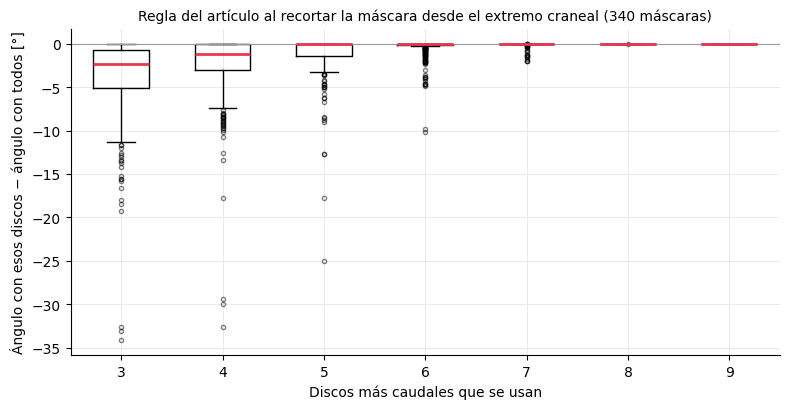

In [ ]:
# 5. El ángulo según cuántos discos entran en la máscara (regla del artículo)
discos_por_mascara = {s: sorted(planos_disco.loc[planos_disco["serie"] == s, "disco"].unique()) for s in planos_disco["serie"].unique()}
print("Discos por máscara única:", pd.Series([len(discos_por_mascara[s]) for s in unicas]).value_counts().sort_index().to_dict())

filas = []
for s in unicas:
    tabla = tabla_de_caras(planos_disco[planos_disco["serie"] == s])
    discos = sorted(tabla.index)
    completo = regla_articulo(tabla)[0]
    for k in range(3, len(discos) + 1):
        filas.append({"serie": s, "estudio": estudio_de[s], "discos_en_mascara": len(discos), "discos_usados": k,
                      "discos_quitados": len(discos) - k, "cobb_articulo": regla_articulo(tabla.loc[discos[:k]])[0],
                      "cobb_todos": completo})
recorte = pd.DataFrame(filas)
recorte["dif"] = recorte["cobb_articulo"] - recorte["cobb_todos"]
recorte.to_csv(DIR_SALIDA / "recorte_de_niveles.csv", index=False)

resumen_recorte = (recorte.groupby("discos_usados")
                   .agg(mascaras=("serie", "size"), mediana_cobb=("cobb_articulo", "median"),
                        mediana_dif=("dif", "median"), p90_abs_dif=("dif", lambda x: x.abs().quantile(0.9)),
                        pct_cambia_mas_de_2=("dif", lambda x: 100 * (x.abs() > 2).mean()),
                        pct_conserva_el_maximo=("dif", lambda x: 100 * (x.abs() < 0.01).mean())))
resumen_recorte.to_csv(DIR_SALIDA / "resumen_recorte_de_niveles.csv")
display(resumen_recorte.round(2))

# Parejas de máscaras distintas de un mismo estudio: con todos los discos y solo con los que comparten
huella = variantes.set_index("serie")["mascara_md5"]
filas = []
for estudio, g in variantes.groupby("estudio"):
    for s1, s2 in itertools.combinations(sorted(g["serie"]), 2):
        if huella[s1] == huella[s2]:
            continue
        t1, t2 = (tabla_de_caras(planos_disco[planos_disco["serie"] == s]) for s in (s1, s2))
        comunes = sorted(set(t1.index) & set(t2.index))
        filas.append({"estudio": estudio, "serie_1": s1, "serie_2": s2, "discos_1": len(t1), "discos_2": len(t2),
                      "misma_cobertura": set(t1.index) == set(t2.index),
                      "dif_todos": regla_articulo(t1)[0] - regla_articulo(t2)[0],
                      "dif_comunes": (regla_articulo(t1.loc[comunes])[0] - regla_articulo(t2.loc[comunes])[0])
                                     if len(comunes) >= 2 else np.nan})
parejas = pd.DataFrame(filas)
parejas.to_csv(DIR_SALIDA / "parejas_por_cobertura.csv", index=False)
resumen_parejas = (parejas.groupby("misma_cobertura")
                   .agg(parejas=("estudio", "size"), estudios=("estudio", "nunique"),
                        mediana_abs_todos=("dif_todos", lambda x: x.abs().median()),
                        max_abs_todos=("dif_todos", lambda x: x.abs().max()),
                        mediana_abs_comunes=("dif_comunes", lambda x: x.abs().median()),
                        max_abs_comunes=("dif_comunes", lambda x: x.abs().max())))
display(resumen_parejas.round(2))
print("Parejas con distinta cobertura:")
print(parejas[~parejas["misma_cobertura"]].assign(orden=lambda d: d["dif_todos"].abs())
      .sort_values("orden", ascending=False).drop(columns="orden").round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
niveles = sorted(recorte["discos_usados"].unique())
ax.boxplot([recorte.loc[recorte["discos_usados"] == k, "dif"] for k in niveles], tick_labels=niveles, widths=0.55,
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.axhline(0, color="#999999", lw=0.8)
ax.set_xlabel("Discos más caudales que se usan")
ax.set_ylabel("Ángulo con esos discos − ángulo con todos [°]")
ax.set_title("Regla del artículo al recortar la máscara desde el extremo craneal (340 máscaras)", fontsize=10)
ejes_limpios(ax)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_recorte_de_niveles.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar las tablas y la gráfica.** La primera línea cuenta cuántas máscaras tienen cada número de discos. En la primera tabla, cada fila es un número de discos usados (los más caudales), y se muestran cuántas máscaras lo permiten, la mediana del ángulo, la mediana de la diferencia con el ángulo de la máscara completa, su percentil 90 en valor absoluto, el porcentaje de máscaras que cambian más de 2° y el porcentaje que conserva exactamente el máximo. La segunda tabla separa las parejas de máscaras distintas de un mismo estudio según tengan o no los mismos discos, y da la diferencia de ángulo con todos los discos y solo con los comunes. La gráfica muestra la diferencia con la máscara completa para cada número de discos usados.

**Resultados.** Casi todas las máscaras tienen entre 6 y 9 discos, y solo `246_t2` tiene 5 y `35_t2`, 3. Al recortar desde arriba, el ángulo se conserva mientras queden al menos seis discos. Con seis, la mediana del cambio es 0 y solo el 6,2 % de las máscaras cambia más de 2°, y con siete, el 0,4 %. En cambio, con cinco discos el 14,8 % cambia más de 2°, con cuatro el 36,3 % y con tres el 56,2 %, con una mediana de −2,3°. El ángulo casi siempre baja, porque quitar niveles quita candidatos al máximo, y en algunas máscaras baja más de 30°, en curvas cuyo extremo craneal queda fuera del recorte. Con la anatomía típica, seis discos corresponden a la región entre L5–S1 y T12–L1.

Entre las parejas de máscaras distintas de un mismo estudio, las 11 con distinta cobertura difieren una mediana de 0,56° con todos sus discos y de 0,24° con los discos comunes, y como máximo 1,88°. Ninguna se acerca a la diferencia de 7,43° que el cuaderno 02 encontró en el estudio 35 con la regla del script, ya que con la regla del artículo `35_t2` (tres discos) da 7,6° y `35_t1` (nueve discos), 9,5°. Es decir, gran parte de aquel caso venía de la regla y no de la cobertura.

Por lo tanto, el número de niveles importa sobre todo cuando la máscara tiene menos de seis discos, y entonces casi siempre subestima, porque una máscara corta no puede ver la parte de la curva que queda fuera de ella.

## Cuaderno 03 · La regla correcta, o por qué el script y el artículo eligen caras distintas

El script ajusta un plano a la mitad inferior y otro a la mitad superior de cada disco, y selecciona el par de caras con la mayor diferencia de inclinación lateral. Para formar cada par, recorre los discos según el orden de sus etiquetas y compara la cara inferior de uno con la cara superior del siguiente.

Con las etiquetas de SPIDER-Baseline-IIS, que aumentan de arriba hacia abajo, el primero de cada par es el disco de arriba. El script compara entonces la cara inferior del disco de arriba con la cara superior del disco de abajo, es decir, las caras internas, que tocan las vértebras incluidas entre los dos discos. Es lo que describe el artículo. Con las etiquetas de SPIDER, que aumentan de abajo hacia arriba, el primero es el disco de abajo, y el script compara las caras externas, es decir, la inferior del disco de abajo con la superior del de arriba. Así se explica que la cara inferior del disco 201, la que toca el sacro, aparezca en el par elegido, aunque con el emparejamiento previsto nunca podría hacerlo.

Si $\theta_{\mathrm{inf},d}$ y $\theta_{\mathrm{sup},d}$ son las inclinaciones laterales de las caras del disco $d$, con los discos numerados de caudal a craneal como en SPIDER, las dos reglas se escriben así.

$$
C_{\mathrm{script}} = \max_{a < b} \left| \theta_{\mathrm{inf},a} - \theta_{\mathrm{sup},b} \right| \qquad\qquad C_{\mathrm{artículo}} = \max_{a < b} \left| \theta_{\mathrm{sup},a} - \theta_{\mathrm{inf},b} \right|
$$

La celda 6 reconstruye las dos reglas a partir de los planos del cuaderno 03 y comprueba tres cosas. La primera es que la regla del script reproduce el ángulo que dio el script en el cuaderno 03, la segunda, que la regla del artículo reproduce la del cuaderno 06, y la tercera, que la regla del script, recorriendo los discos de arriba hacia abajo, da exactamente la regla del artículo.

In [ ]:
# 6. Las dos reglas a partir de los planos del cuaderno 03, y la prueba de que solo difieren en el orden de los discos
filas = []
for s in unicas:
    tabla = tabla_de_caras(planos_disco[planos_disco["serie"] == s])
    sc, ar = regla_script(tabla), regla_articulo(tabla)
    inv = maximo_entre_discos(tabla, "inferior", "superior", "craneal_a_caudal")   # el script con la numeración de IIS
    ar_b = regla_articulo(tabla_de_caras(planos_disco[planos_disco["serie"] == s], "arcsen_nx"))
    filas.append({"serie": s, "estudio": estudio_de[s], "n_discos": len(tabla), "disco_mas_craneal": int(tabla.index.max()),
                  "cobb_script": sc[0], "disco_inf_script": sc[1], "disco_sup_script": sc[2],
                  "cobb_articulo": ar[0], "disco_inf_articulo": ar[1], "disco_sup_articulo": ar[2],
                  "cobb_script_invertido": inv[0], "disco_inf_invertido": inv[2], "disco_sup_invertido": inv[1],
                  "cobb_articulo_arcsen": ar_b[0]})
reglas = pd.DataFrame(filas).set_index("serie")
reglas["usa_cara_inferior_201"] = reglas["disco_inf_script"] == 201
reglas["dif_script_menos_articulo"] = reglas["cobb_script"] - reglas["cobb_articulo"]
reglas["mismo_par"] = ((reglas["disco_inf_script"] == reglas["disco_inf_articulo"])
                       & (reglas["disco_sup_script"] == reglas["disco_sup_articulo"]))

v03 = variantes.set_index("serie").loc[unicas]
comprobaciones = pd.DataFrame([
    {"comprobación": "regla del script frente al ángulo del script en el cuaderno 03",
     "diferencia_maxima_grados": (reglas["cobb_script"] - v03["angulo_original"]).abs().max(),
     "mismo_par_pct": 100 * ((reglas["disco_inf_script"] == v03["disco_inf_original"])
                             & (reglas["disco_sup_script"] == v03["disco_sup_original"])).mean()},
    {"comprobación": "regla del artículo frente a la del cuaderno 06",
     "diferencia_maxima_grados": (reglas["cobb_articulo"] - cobb_06.loc[unicas, "cobb_articulo"]).abs().max(),
     "mismo_par_pct": 100 * ((reglas["disco_inf_articulo"] == cobb_06.loc[unicas, "disco_inf_articulo"])
                             & (reglas["disco_sup_articulo"] == cobb_06.loc[unicas, "disco_sup_articulo"])).mean()},
    {"comprobación": "regla del script recorriendo los discos de arriba hacia abajo frente a la del artículo",
     "diferencia_maxima_grados": (reglas["cobb_script_invertido"] - reglas["cobb_articulo"]).abs().max(),
     "mismo_par_pct": 100 * ((reglas["disco_inf_invertido"] == reglas["disco_inf_articulo"])
                             & (reglas["disco_sup_invertido"] == reglas["disco_sup_articulo"])).mean()},
])
reglas.reset_index().to_csv(DIR_SALIDA / "reglas_por_mascara.csv", index=False)
display(comprobaciones.round(6))

,comprobación,diferencia_maxima_grados,mismo_par_pct
0,regla del script frente al ángulo del script e...,0.0,100.0
1,regla del artículo frente a la del cuaderno 06,0.0,100.0
2,regla del script recorriendo los discos de arr...,0.0,100.0


**Cómo interpretar la tabla.** Cada fila es una comprobación sobre las 340 máscaras únicas. `diferencia_maxima_grados` es la mayor diferencia, en valor absoluto, entre los dos ángulos que se comparan, y `mismo_par_pct` es el porcentaje de máscaras en las que los dos eligen el mismo par de discos. Las dos primeras filas confirman que las reglas reconstruidas aquí son las mismas de los cuadernos 03 y 06, y la tercera pone a prueba la explicación de los autores.

**Resultados.** Las tres comprobaciones coinciden en las 340 máscaras, con diferencias del orden del redondeo numérico y el mismo par en el 100 % de los casos. La regla del script, recorriendo los discos de arriba hacia abajo como lo haría con las etiquetas de SPIDER-Baseline-IIS, es exactamente la regla del artículo.

Esto confirma que la diferencia entre las dos reglas se debe solo al orden en que se recorren los discos, como explicó Jasper van der Graaf. Es una comprobación sobre los planos, no una nueva ejecución del script sobre máscaras renumeradas. Sin embargo, como la regla del script reproduce exactamente el ángulo del cuaderno 03, no hay otra parte del cálculo que pueda separarlas.

,grupo,media_script,media_articulo,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs,mas_de_2,mas_de_5,mismo_par_pct
0,todas,8.42,8.03,340,218,0.39,0.23 a 0.58,-2.30,3.08,0.71,2.09,8.15,40,4,44.41
1,par del script con la cara inferior del 201,7.31,6.81,141,94,0.50,0.17 a 0.87,-2.77,3.77,0.77,2.33,8.15,22,3,51.06
2,resto,9.21,8.90,199,133,0.31,0.13 a 0.48,-1.86,2.49,0.68,1.96,5.02,18,1,39.70


Máscaras con la mayor diferencia (script − artículo):
              cobb_script  disco_inf_script  disco_sup_script  cobb_articulo  disco_inf_articulo  disco_sup_articulo  dif_script_menos_articulo
serie                                                                                                                                          
162_t2_SPACE        36.87               201               204          28.72                 201                 204                       8.15
162_t1              34.57               201               204          26.63                 201                 204                       7.94
35_t2               15.41               201               203           7.64                 201                 203                       7.77
186_t1              46.47               204               207          41.46                 203                 207                       5.02
209_t1               9.36               201               208           4.96      

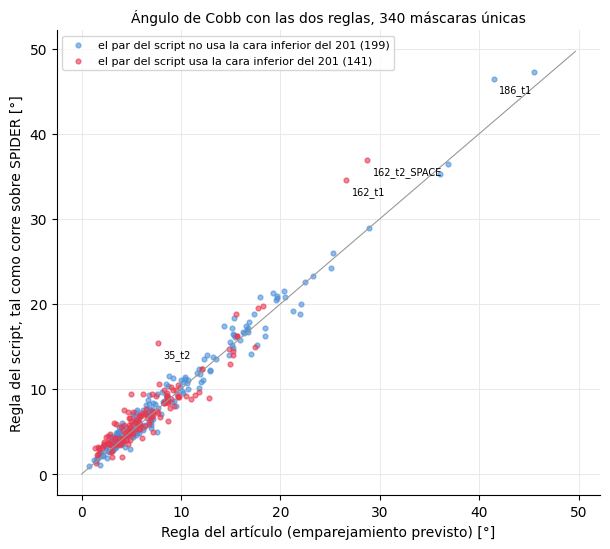

In [ ]:
# 7. Cuánto cambia el ángulo al usar la regla correcta
filas = []
for nombre, g in (("todas", reglas), ("par del script con la cara inferior del 201", reglas[reglas["usa_cara_inferior_201"]]),
                  ("resto", reglas[~reglas["usa_cara_inferior_201"]])):
    filas.append({"grupo": nombre, "media_script": g["cobb_script"].mean(), "media_articulo": g["cobb_articulo"].mean(),
                  **bland_altman(g, "dif_script_menos_articulo"),
                  "mas_de_2": int((g["dif_script_menos_articulo"].abs() > 2).sum()),
                  "mas_de_5": int((g["dif_script_menos_articulo"].abs() > 5).sum()),
                  "mismo_par_pct": 100 * g["mismo_par"].mean()})
cambio_regla = pd.DataFrame(filas)
cambio_regla.to_csv(DIR_SALIDA / "script_frente_a_articulo.csv", index=False)
display(cambio_regla.round(2))
print("Máscaras con la mayor diferencia (script − artículo):")
print(reglas.sort_values("dif_script_menos_articulo", ascending=False).head(6)
      [["cobb_script", "disco_inf_script", "disco_sup_script", "cobb_articulo", "disco_inf_articulo", "disco_sup_articulo",
        "dif_script_menos_articulo"]].round(2).to_string())

fig, ax = plt.subplots(figsize=(6.2, 5.6))
lim = reglas[["cobb_script", "cobb_articulo"]].max().max() * 1.05
ax.plot([0, lim], [0, lim], color="#999999", lw=0.8)
for usa, color, etiqueta in ((False, "#4a90d9", "el par del script no usa la cara inferior del 201"),
                             (True, "#e8384f", "el par del script usa la cara inferior del 201")):
    g = reglas[reglas["usa_cara_inferior_201"] == usa]
    ax.scatter(g["cobb_articulo"], g["cobb_script"], s=12, alpha=0.6, color=color, label=f"{etiqueta} ({len(g)})")
for s, f in reglas.sort_values("dif_script_menos_articulo", ascending=False).head(4).iterrows():
    ax.annotate(s, (f["cobb_articulo"], f["cobb_script"]), fontsize=7, xytext=(4, -10), textcoords="offset points")
ax.set_xlabel("Regla del artículo (emparejamiento previsto) [°]")
ax.set_ylabel("Regla del script, tal como corre sobre SPIDER [°]")
ax.set_title("Ángulo de Cobb con las dos reglas, 340 máscaras únicas", fontsize=10)
ax.legend(fontsize=8)
ejes_limpios(ax)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_script_frente_a_articulo.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar la tabla y la gráfica.** Cada fila resume la diferencia entre el ángulo con la regla del script y con la del artículo (script menos artículo) en un grupo de máscaras, que son todas, aquellas en las que el par del script usa la cara inferior del disco 201 y el resto. Se muestran las medias de los dos ángulos, el sesgo con su intervalo de confianza (*bootstrap* por estudio), los límites de acuerdo, la mediana y el percentil 90 de la diferencia absoluta, cuántas máscaras cambian más de 2° y de 5°, y en qué porcentaje coincide el par. En la gráfica, cada punto es una máscara. Los puntos sobre la diagonal tienen el mismo ángulo con las dos reglas, y se rotulan los cuatro con la mayor diferencia.

**Resultados.** En promedio, la regla del script da 8,42° y la del artículo 8,03°, de modo que el emparejamiento invertido infla el ángulo 0,39° (IC del 95 % de 0,23° a 0,58°). El cambio va más a menudo hacia arriba (209 máscaras) que hacia abajo (118), y suele ser pequeño, con una mediana de la diferencia absoluta de 0,71°. Aun así, supera los 2° en 40 máscaras y los 5° en cuatro, y el par elegido coincide solo en el 44 % de ellas. En las 141 máscaras en las que el par del script usa la cara inferior del disco 201, el aumento medio es de 0,50°, y en el resto, de 0,31°. Es decir, el problema no está solo en el disco 201, porque el script usa la cara equivocada en los dos extremos del par.

Las mayores diferencias aparecen en el estudio 162 (36,9° frente a 28,7° en T2 SPACE y 34,6° frente a 26,6° en T1), en `35_t2` (15,4° frente a 7,6°), en `186_t1` (46,5° frente a 41,5°) y en `209_t1` (9,4° frente a 5,0°). Con la regla del artículo, el estudio 162 sigue siendo el de mayor ángulo entre las 141 máscaras en las que el script usaba la cara inferior del 201, pero con unos 8° menos que con el script.

## Cuaderno 03 · Evitar el disco 201 frente a la regla correcta

En la segunda semana, la variante A quitaba la cara inferior del disco 201 de la regla del script, la variante B cambiaba la fórmula de la inclinación por $\arcsin(n_x)$ y la variante AB combinaba las dos. Ahora que se conoce la causa, se puede comprobar cuál de esas correcciones se acerca al emparejamiento previsto. La celda 8 compara, en las mismas 340 máscaras, el script tal como corre sobre SPIDER, las tres variantes, la regla del artículo con las dos fórmulas y el ángulo por platillos del cuaderno 06, que se mide sin usar ninguna de las dos reglas.

,medida,media,mediana,dif_media_vs_articulo_todas,dif_mediana_vs_articulo_todas,por_debajo_todas,por_encima_todas,dif_media_vs_articulo_con_201,dif_mediana_vs_articulo_con_201,por_debajo_con_201,por_encima_con_201
0,script,8.42,6.45,0.39,0.30,118,209,0.50,0.32,51,86
1,variante_A_sin_201,7.56,5.43,-0.47,-0.16,182,145,-1.58,-1.22,115,22
2,variante_B_arcsen,7.92,6.02,-0.11,0.02,161,160,-0.46,-0.35,84,50
3,variante_AB,7.42,5.27,-0.61,-0.31,193,129,-1.68,-1.33,116,19
4,articulo,8.03,5.93,0.00,0.00,0,0,0.00,0.00,0,0
5,articulo_arcsen,7.65,5.64,-0.38,-0.15,244,7,-0.64,-0.33,104,6
6,platillos,8.29,6.28,0.26,0.24,120,206,0.37,0.20,46,88


Estudio 162:
              script  variante_A_sin_201  variante_B_arcsen  variante_AB  articulo  articulo_arcsen  platillos
serie                                                                                                         
162_t1         34.57               10.76              21.23        10.65     26.63            19.43      23.71
162_t2_SPACE   36.87               11.59              22.51        11.48     28.72            21.00      25.90


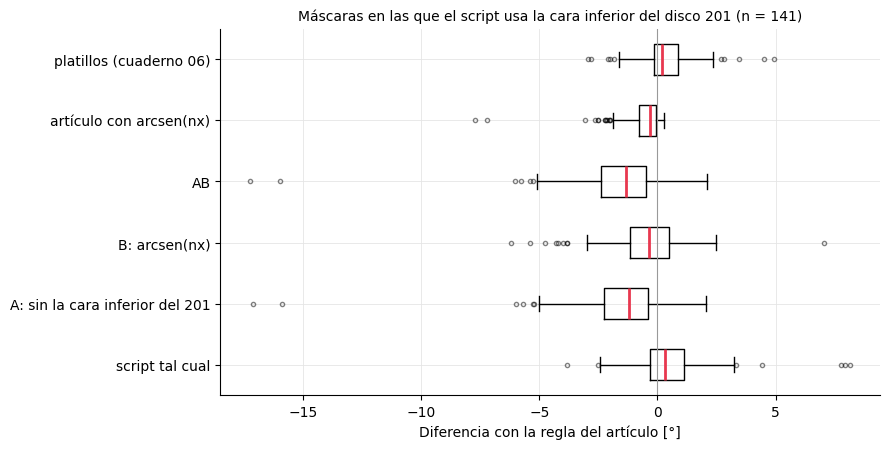

In [ ]:
# 8. Variantes del cuaderno 03, regla del artículo y platillos, máscara por máscara
lado_a_lado = pd.DataFrame({
    "estudio": reglas["estudio"],
    "usa_cara_inferior_201": reglas["usa_cara_inferior_201"],
    "script": v03["angulo_original"],
    "variante_A_sin_201": v03["angulo_A_sin_201"],
    "variante_B_arcsen": v03["angulo_B_arcsen"],
    "variante_AB": v03["angulo_AB"],
    "articulo": reglas["cobb_articulo"],
    "articulo_arcsen": reglas["cobb_articulo_arcsen"],
    "platillos": cobb_06.loc[unicas, "cobb_platillos"],
})
MEDIDAS = ["script", "variante_A_sin_201", "variante_B_arcsen", "variante_AB", "articulo", "articulo_arcsen", "platillos"]
lado_a_lado.reset_index().to_csv(DIR_SALIDA / "variantes_frente_a_articulo.csv", index=False)

filas = []
for medida in MEDIDAS:
    fila = {"medida": medida, "media": lado_a_lado[medida].mean(), "mediana": lado_a_lado[medida].median()}
    for nombre, g in (("todas", lado_a_lado), ("con_201", lado_a_lado[lado_a_lado["usa_cara_inferior_201"]])):
        d = g[medida] - g["articulo"]
        fila[f"dif_media_vs_articulo_{nombre}"] = d.mean()
        fila[f"dif_mediana_vs_articulo_{nombre}"] = d.median()
        fila[f"por_debajo_{nombre}"] = int((d < -0.05).sum())
        fila[f"por_encima_{nombre}"] = int((d > 0.05).sum())
    filas.append(fila)
resumen_variantes = pd.DataFrame(filas)
resumen_variantes.to_csv(DIR_SALIDA / "resumen_variantes_frente_a_articulo.csv", index=False)
display(resumen_variantes.round(2))
print("Estudio 162:")
print(lado_a_lado[lado_a_lado["estudio"] == 162][MEDIDAS].round(2).to_string())

con_201 = lado_a_lado[lado_a_lado["usa_cara_inferior_201"]]
fig, ax = plt.subplots(figsize=(9, 4.6))
comparadas = ["script", "variante_A_sin_201", "variante_B_arcsen", "variante_AB", "articulo_arcsen", "platillos"]
ax.boxplot([con_201[m] - con_201["articulo"] for m in comparadas], vert=False, widths=0.5,
           tick_labels=["script tal cual", "A: sin la cara inferior del 201", "B: arcsen(nx)", "AB",
                        "artículo con arcsen(nx)", "platillos (cuaderno 06)"],
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.axvline(0, color="#999999", lw=0.8)
ax.set_xlabel("Diferencia con la regla del artículo [°]")
ax.set_title(f"Máscaras en las que el script usa la cara inferior del disco 201 (n = {len(con_201)})", fontsize=10)
ejes_limpios(ax)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_variantes_frente_a_articulo.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar la tabla y la gráfica.** Cada fila de la tabla es una forma de calcular el ángulo. Se muestran su media y su mediana en las 340 máscaras y su diferencia con la regla del artículo (media, mediana y cuántas máscaras quedan por debajo o por encima, con una tolerancia de 0,05°), en todas las máscaras y solo en las 141 en las que el script usa la cara inferior del disco 201. La gráfica muestra esa diferencia en las 141 máscaras, y la línea vertical en cero corresponde a la regla del artículo.

**Resultados.** Quitar la cara inferior del disco 201 (variante A) baja el ángulo medio de 8,42° a 7,56°, por debajo de la regla del artículo (8,03°) y de los platillos (8,29°). En las 141 máscaras en las que actúa, queda en promedio 1,58° por debajo de la regla del artículo y 1,95° por debajo de los platillos, y queda por debajo en 115 de ellas. La razón es que la variante A elimina candidatos sin cambiar el emparejamiento. Deja fuera la cara equivocada, pero también se pierde la cara superior del disco 201, que es la que toca el platillo de la vértebra de abajo. El estudio 162 lo muestra con claridad, ya que con la variante A baja a 10,8° y 11,6°, mientras que la regla del artículo da 26,6° y 28,7° y los platillos, 23,7° y 25,9°.

La fórmula importa menos que el emparejamiento, pero no es despreciable. Con la regla del artículo, cambiar $\arctan(n_x/n_z)$ por $\arcsin(n_x)$ baja el ángulo en promedio 0,38° (mediana 0,15°) y lo baja en 244 de las 340 máscaras. En el estudio 162 lo reduce unos 7° (de 26,6° a 19,4° y de 28,7° a 21,0°), porque sus caras tienen mucha inclinación sagital. La sección sobre la fórmula, más adelante, se ocupa de esa elección.

Por lo tanto, la corrección adecuada no es evitar el disco 201, sino usar el emparejamiento previsto. La regla del artículo cambia la cara equivocada por la correcta y, además, es la que más se acerca al ángulo por platillos, que se calcula sin depender de ninguna de las dos reglas.

Con esto también deja de importar una duda menor del cuaderno 03, que era si la cara inferior del 201 tenía más vértices que las demás por el tamaño del disco o por su inclinación. La regla del artículo nunca usa esa cara, así que su número de vértices ya no influye en el ángulo.

## Cuaderno 03 · El disco más craneal de la máscara

En el cuaderno 03 quedó abierta una pregunta. En 115 de las 340 máscaras, la cara superior del par elegido por el script pertenecía al disco más craneal de la máscara, que puede estar cortado por el campo de visión. Como el script usaba la cara superior de ese disco, que es la más expuesta al borde de la imagen, cabía pensar que la regla correcta resolviera parte del problema. Sin embargo, la regla del artículo también puede usar ese disco, ahora por su cara inferior.

Para responder esta pregunta no basta con contar cuántas veces se selecciona ese disco, sino que también hay que comprobar si está realmente cortado por el campo de visión. Las celdas 9 y 10 leen cada máscara, la reorientan como el script y comprueban si cada disco toca el borde de la imagen, ya sea por arriba o por abajo (borde craneocaudal) o por los lados (primer o último corte sagital). Un disco que toca el primer o el último corte sagital continúa fuera de la imagen, así que su cara puede estar incompleta. La celda 11 relaciona esa cobertura con el par elegido y mide cuánto cambia el ángulo si se excluye la cara del disco más craneal.

In [ ]:
# 9. Verificar masks.zip y extraer las máscaras únicas a disco local (también las usa la sección de los platillos)
import hashlib, zipfile

def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

assert md5_archivo(ZIP_MASCARAS) == MD5_MASKS_ZIP, "masks.zip no coincide con la huella verificada contra Zenodo"
DIR_LOCAL.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_MASCARAS) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    assert len(miembros) == N_ESPERADO, f"Se esperaban {N_ESPERADO} máscaras en el zip y hay {len(miembros)}"
    for s in unicas:
        datos = z.read(miembros[f"{s}.mha"])
        assert hashlib.md5(datos).hexdigest() == huella[s], f"{s}: la máscara no coincide con la del cuaderno 03"
        (DIR_LOCAL / f"{s}.mha").write_bytes(datos)
print(f"{len(unicas)} máscaras únicas en {DIR_LOCAL}, idénticas a las que usó el cuaderno 03")

340 máscaras únicas en /content/mascaras_unicas, idénticas a las que usó el cuaderno 03


In [ ]:
# 10. Cobertura de cada disco: ¿toca el borde de la imagen?
from tiger.io import read_image
from tiger.resampling import reorient_image, resample_mask

def reorientada(ruta):
    "Máscara reorientada como en el script, sin remuestrear (ejes del arreglo: x lateral, y anteroposterior, z craneocaudal)."
    mascara, cab = read_image(str(ruta))
    return reorient_image(mascara, cab, interpolation="nearest")

def cobertura_de(mascara, serie):
    """Para cada disco: si toca el borde craneal, el caudal o un borde lateral (primer o último corte sagital) de la
    imagen, y en cuántos cortes sagitales aparece. El lado craneal se decide con los discos (el 201 es el más caudal)."""
    discos = sorted(int(l) for l in np.unique(mascara) if l > 200)
    z_medio = {d: np.nonzero(mascara == d)[2].mean() for d in discos}
    craneal_arriba = z_medio[discos[-1]] > z_medio[discos[0]]
    nx, _, nz = mascara.shape
    filas = []
    for d in discos:
        x, _, z = np.nonzero(mascara == d)
        filas.append({"serie": serie, "disco": d, "es_el_mas_craneal": d == discos[-1],
                      "toca_borde_craneal": bool(z.max() == nz - 1) if craneal_arriba else bool(z.min() == 0),
                      "toca_borde_caudal": bool(z.min() == 0) if craneal_arriba else bool(z.max() == nz - 1),
                      "toca_borde_lateral": bool(x.min() == 0 or x.max() == nx - 1),
                      "cortes_sagitales_con_disco": int(len(np.unique(x))), "cortes_sagitales_imagen": int(nx),
                      "voxeles": int(len(x))})
    return filas

t0, filas, errores = time.time(), [], []
for k, s in enumerate(unicas, 1):
    try:
        filas += cobertura_de(reorientada(DIR_LOCAL / f"{s}.mha")[0], s)
    except Exception as e:
        errores.append((s, f"{type(e).__name__}: {e}"[:200]))
    if k % 50 == 0:
        print(f"[{k}/{len(unicas)}] {(time.time() - t0) / 60:.1f} min")
cobertura = pd.DataFrame(filas)
cobertura["cortado"] = cobertura["toca_borde_craneal"] | cobertura["toca_borde_lateral"]
cobertura.to_csv(DIR_SALIDA / "cobertura_por_disco.csv", index=False)
print(f"Listo en {(time.time() - t0) / 60:.1f} min · errores: {errores or 'ninguno'}")

grupo_disco = np.where(cobertura["es_el_mas_craneal"], "disco más craneal",
                       np.where(cobertura["disco"] == 201, "disco 201", "discos intermedios"))
resumen_cobertura = (cobertura.assign(grupo=grupo_disco)
                     .groupby("grupo")[["toca_borde_craneal", "toca_borde_caudal", "toca_borde_lateral", "cortado"]]
                     .mean().mul(100).round(1))
resumen_cobertura["discos"] = cobertura.assign(grupo=grupo_disco).groupby("grupo").size()
display(resumen_cobertura)

[50/340] 0.7 min
[100/340] 1.7 min
[150/340] 2.6 min
[200/340] 3.4 min
[250/340] 4.0 min
[300/340] 4.9 min
Listo en 5.4 min · errores: ninguno


,toca_borde_craneal,toca_borde_caudal,toca_borde_lateral,cortado,discos
grupo,,,,,
disco 201,0.0,0.0,7.1,7.1,340
disco más craneal,4.1,0.0,1.8,5.3,340
discos intermedios,0.0,0.0,4.1,4.1,1736


**Cómo interpretar la tabla.** Cada fila agrupa los discos según su posición en la máscara, que puede ser el 201 (el más caudal), el más craneal o los intermedios. Las columnas indican el porcentaje de discos de cada grupo que tocan el borde craneal, el caudal o un borde lateral de la imagen, y `cortado` cuenta los que tocan el borde craneal o uno lateral, los dos que pueden dejar incompleta una cara usada por la regla del artículo.

**Resultados.** Ningún disco toca el borde caudal, lo que es coherente con que el campo de visión de una RM lumbar incluya el sacro. El borde craneal solo lo toca el disco más craneal, en 14 de las 340 máscaras (4,1 %). El borde lateral, en cambio, aparece en los tres grupos, en el 7,1 % de los discos 201, el 4,1 % de los intermedios y el 1,8 % de los más craneales. En total, el disco más craneal está cortado, por el borde craneal o por uno lateral, en 18 máscaras (5,3 %), una proporción del mismo orden que la de los demás discos. La tabla no dice por qué un disco llega al borde lateral. Puede ser un campo de visión estrecho, como en `35_t2`, o una columna desplazada hacia un lado, y este cuaderno no separa esas causas.

El par usa el disco más craneal: 115 máscaras con la regla del script y 121 con la del artículo (de 340)
Disco más craneal cortado: 18 máscaras (borde craneal 14, lateral 6)
El par del artículo incluye algún disco cortado (craneal o lateral): 23 máscaras
Entre las 121 máscaras en las que la regla del artículo usa el disco más craneal, correlación de Spearman entre el ángulo y lo que baja al quitarlo: 0.41
        cobb_articulo  cobb_articulo_sin_craneal  cambio_sin_craneal  craneal_cortado
serie                                                                                
1_t1            45.50                      35.35               10.16            False
186_t1          41.46                      31.62                9.83            False
160_t1          28.90                      19.86                9.04            False
196_t1          11.43                       6.39                5.04            False
253_t1          18.49                      13.84                4.65       

,articulo_usa_disco_mas_craneal,disco_mas_craneal_cortado,mascaras,cambio_medio_sin_craneal,cambio_mediano_sin_craneal,cambian_mas_de_2
0,True,True,2,1.83,1.83,1
1,True,False,119,1.31,0.79,19
2,False,True,16,0.00,0.00,0
3,False,False,203,0.00,0.00,0


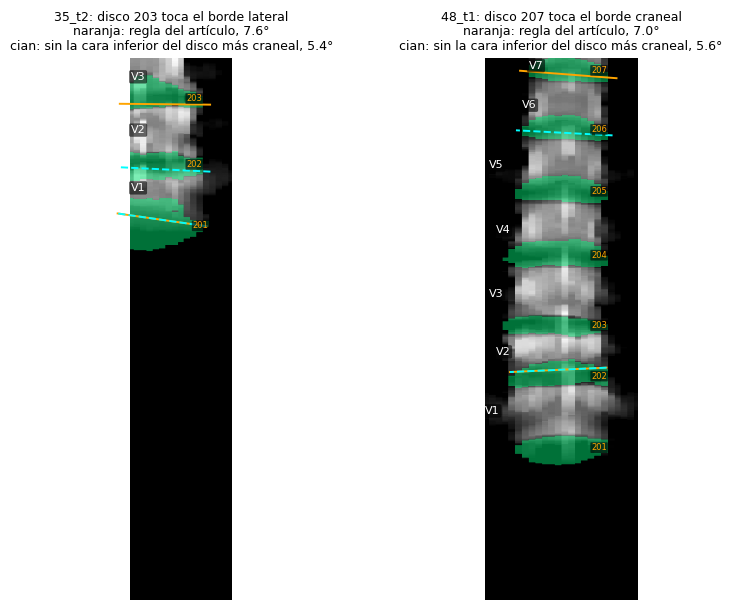

In [ ]:
# 11. ¿Influye un disco cortado en el par elegido y en el ángulo?
def rotular_vertebras(ax, mascara, vista, x_corte=None, discos=False):
    """Escribe la etiqueta de SPIDER sobre cada vértebra (V1 = la más caudal; no es un nivel anatómico) y, si
    discos=True, el número de cada disco. vista: "coronal" (proyección) o "sagital" (corte en x_corte).
    Se llama después de invertir el eje, si se invierte: las vértebras van al borde izquierdo y los discos al derecho."""
    datos = mascara[x_corte] if vista == "sagital" else mascara
    invertido = ax.xaxis_inverted()
    for l in (int(v) for v in np.unique(datos)):
        es_disco = l > 200
        if l == 0 or l == 100 or (es_disco and not discos):
            continue
        idx = np.argwhere(datos == l)
        h, z = (idx[:, 0], idx[:, 1]) if vista == "sagital" else (idx[:, 0], idx[:, 2])
        izquierda, derecha = (h.max(), h.min()) if invertido else (h.min(), h.max())
        if es_disco:
            ax.text(derecha, np.median(z), str(l), fontsize=6, color="orange", ha="right", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.1", "fc": "black", "ec": "none", "alpha": 0.6})
        else:
            ax.text(izquierda, np.median(z), f"V{l}", fontsize=8, color="white", ha="left", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "black", "ec": "none", "alpha": 0.6})

def dibujar_plano(ax, fila, color, largo=50, **kw):
    "Traza en la proyección coronal la línea de un plano (normal nx, nz; punto px, pz), en vóxeles de 0,5 mm."
    d = np.array([fila["nz"], -fila["nx"]]) / np.hypot(fila["nx"], fila["nz"])
    ax.plot([fila["px"] - largo * d[0], fila["px"] + largo * d[0]],
            [fila["pz"] - largo * d[1], fila["pz"] + largo * d[1]], color=color, lw=1.4, **kw)

craneal = cobertura[cobertura["es_el_mas_craneal"]].set_index("serie")
cortados = cobertura[cobertura["cortado"]].groupby("serie")["disco"].apply(set)
filas = []
for s in unicas:
    tabla = tabla_de_caras(planos_disco[planos_disco["serie"] == s])
    top = int(craneal.loc[s, "disco"])
    sin_top = regla_articulo(tabla, excluir={(top, "inferior")})
    r = reglas.loc[s]
    filas.append({"serie": s, "estudio": r["estudio"], "disco_mas_craneal": top,
                  "craneal_cortado": bool(craneal.loc[s, "cortado"]),
                  "craneal_toca_borde_craneal": bool(craneal.loc[s, "toca_borde_craneal"]),
                  "craneal_toca_borde_lateral": bool(craneal.loc[s, "toca_borde_lateral"]),
                  "articulo_usa_craneal": r["disco_sup_articulo"] == top,
                  "script_usa_craneal": r["disco_sup_script"] == top,
                  "par_articulo_con_disco_cortado": bool({r["disco_inf_articulo"], r["disco_sup_articulo"]}
                                                         & cortados.get(s, set())),
                  "cobb_articulo": r["cobb_articulo"], "cobb_articulo_sin_craneal": sin_top[0],
                  "cambio_sin_craneal": r["cobb_articulo"] - sin_top[0]})
extremo = pd.DataFrame(filas).set_index("serie")
extremo.reset_index().to_csv(DIR_SALIDA / "extremo_craneal_por_mascara.csv", index=False)

print(f"El par usa el disco más craneal: {extremo['script_usa_craneal'].sum()} máscaras con la regla del script y "
      f"{extremo['articulo_usa_craneal'].sum()} con la del artículo (de {len(extremo)})")
print(f"Disco más craneal cortado: {extremo['craneal_cortado'].sum()} máscaras "
      f"(borde craneal {extremo['craneal_toca_borde_craneal'].sum()}, lateral {extremo['craneal_toca_borde_lateral'].sum()})")
print(f"El par del artículo incluye algún disco cortado (craneal o lateral): {extremo['par_articulo_con_disco_cortado'].sum()} máscaras")
usa = extremo[extremo["articulo_usa_craneal"]]
print(f"Entre las {len(usa)} máscaras en las que la regla del artículo usa el disco más craneal, correlación de Spearman "
      f"entre el ángulo y lo que baja al quitarlo: {usa['cobb_articulo'].corr(usa['cambio_sin_craneal'], method='spearman'):.2f}")
print(usa.sort_values("cambio_sin_craneal", ascending=False).head(6)
      [["cobb_articulo", "cobb_articulo_sin_craneal", "cambio_sin_craneal", "craneal_cortado"]].round(2).to_string())

filas = []
for usa_c in (True, False):
    for cortado in (True, False):
        g = extremo[(extremo["articulo_usa_craneal"] == usa_c) & (extremo["craneal_cortado"] == cortado)]
        filas.append({"articulo_usa_disco_mas_craneal": usa_c, "disco_mas_craneal_cortado": cortado, "mascaras": len(g),
                      "cambio_medio_sin_craneal": g["cambio_sin_craneal"].mean(),
                      "cambio_mediano_sin_craneal": g["cambio_sin_craneal"].median(),
                      "cambian_mas_de_2": int((g["cambio_sin_craneal"] > 2).sum())})
tabla_extremo = pd.DataFrame(filas)
tabla_extremo.to_csv(DIR_SALIDA / "resumen_extremo_craneal.csv", index=False)
display(tabla_extremo.round(2))

# Panel: las máscaras con disco craneal cortado en las que más cambia el ángulo al excluirlo (hasta tres)
casos = (extremo[extremo["articulo_usa_craneal"] & extremo["craneal_cortado"]]
         .sort_values("cambio_sin_craneal", ascending=False).head(3).index.tolist())
if casos:
    fig, axes = plt.subplots(1, len(casos), figsize=(5.2 * len(casos), 6.2), squeeze=False)
    for ax, s in zip(axes[0], casos):
        mascara, cab = reorientada(DIR_LOCAL / f"{s}.mha")
        mascara = resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))     # mismo espacio que los planos del cuaderno 03
        ax.imshow(((mascara > 0) & (mascara < 100)).sum(1).T, cmap="gray", origin="lower")
        ax.imshow(np.ma.masked_equal((mascara > 200).any(1).T, 0), cmap="winter", vmin=0, vmax=1, alpha=0.45, origin="lower")
        caras = planos_disco[planos_disco["serie"] == s].set_index(["disco", "cara"])
        r, e = reglas.loc[s], extremo.loc[s]
        sin_top = regla_articulo(tabla_de_caras(planos_disco[planos_disco["serie"] == s]),
                                 excluir={(int(e["disco_mas_craneal"]), "inferior")})
        dibujar_plano(ax, caras.loc[(r["disco_inf_articulo"], "superior")], "orange")
        dibujar_plano(ax, caras.loc[(r["disco_sup_articulo"], "inferior")], "orange")
        dibujar_plano(ax, caras.loc[(sin_top[1], "superior")], "cyan", ls="--")
        dibujar_plano(ax, caras.loc[(sin_top[2], "inferior")], "cyan", ls="--")
        ax.invert_xaxis()
        rotular_vertebras(ax, mascara, "coronal", discos=True)
        borde = " y ".join(b for b, v in (("craneal", e["craneal_toca_borde_craneal"]),
                                          ("lateral", e["craneal_toca_borde_lateral"])) if v)
        ax.set_title(f"{s}: disco {int(e['disco_mas_craneal'])} toca el borde {borde}\n"
                     f"naranja: regla del artículo, {r['cobb_articulo']:.1f}°\n"
                     f"cian: sin la cara inferior del disco más craneal, {sin_top[0]:.1f}°", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(DIR_SALIDA / "panel_extremo_craneal.png", dpi=110, facecolor="white", bbox_inches="tight")
    plt.show()

**Cómo interpretar los resultados.** Las primeras líneas comparan cuántas veces usa el disco más craneal cada regla y cuántas máscaras tienen ese disco, o alguno del par elegido, cortado por el campo de visión. Después se muestra la correlación entre el ángulo y lo que baja al quitar ese disco, y las seis máscaras en las que más baja. La tabla separa las máscaras según si la regla del artículo usa el disco más craneal y si ese disco está cortado, y `cambio_*_sin_craneal` indica cuánto baja el ángulo al excluir su cara inferior. El panel muestra, en proyección coronal, las máscaras con disco craneal cortado en las que la regla del artículo lo usa. En naranja aparecen las caras del par de la regla del artículo y en cian discontinuo, las del par que queda al excluir el disco más craneal.

**Resultados.** Con la regla del artículo, el par usa el disco más craneal en 121 máscaras, algo más que las 115 del script, así que la regla correcta no hace desaparecer la pregunta. Sin embargo, solo en dos de esas 121 máscaras el disco está cortado, `35_t2` por el borde lateral y `48_t1` por el craneal. Al excluir su cara inferior, el ángulo baja 2,2° y 1,4°. Hay que tener en cuenta, además, que la regla del artículo usa la cara inferior de ese disco, que es la más alejada del borde craneal.

En las 119 máscaras restantes el disco está completo, y aun así excluirlo baja el ángulo 1,31° en promedio (mediana 0,79°) y más de 2° en 19 de ellas. Ese cambio es mayor cuanto mayor es el ángulo (Spearman 0,41), y los casos más llamativos son `1_t1` (de 45,5° a 35,3°), `186_t1` (de 41,5° a 31,6°) y `160_t1` (de 28,9° a 19,9°). Quitar un extremo del rango baja el máximo por construcción, así que esa caída no indica por sí sola que la cara sea poco confiable.

Por lo tanto, el corte por el campo de visión no explica por qué el disco más craneal aparece tan a menudo en el par. Una explicación compatible con los datos es que, en las curvas más grandes, la vértebra límite craneal está en el borde del campo de visión o por encima, de modo que el ángulo lumbar se queda corto frente a la curva completa. Los propios autores mencionan esta limitación, ya que el campo de visión de una RM lumbar es menor que el de una radiografía y la curva puede continuar fuera de él. La sección del cuaderno 02 muestra el mismo efecto desde el otro lado, porque con menos niveles el ángulo baja. Comprobarlo requiere imágenes con más cobertura craneal o un ángulo de referencia, que SPIDER no tiene. El criterio de corte usado (tocar el borde de la imagen) tampoco detecta discos segmentados de forma incompleta lejos del borde.

## Cuaderno 03 · La fórmula de la inclinación

El script calcula la inclinación lateral de cada cara como $\arctan(n_x/n_z)$, donde $n$ es la normal del plano. El cuaderno 03 mostró que esa expresión crece con la inclinación sagital de la cara, y propuso como alternativa $\arcsin(n_x)$, que es el ángulo entre la normal y el plano sagital. Las dos coinciden cuando la cara no está inclinada hacia delante o hacia atrás, y se separan en las caras muy inclinadas, como la superior del disco 201 en las columnas con mucha lordosis.

El artículo no resuelve de forma inequívoca esta elección. En los métodos dice que los planos se proyectan sobre el plano coronal y se toma su ángulo, que es lo que hace $\arctan(n_x/n_z)$, es decir, la traza del plano en un corte coronal. En la discusión dice que el ángulo coronal que se extrae "no está influido por ninguna inclinación sagital", que describe mejor a $\arcsin(n_x)$. Los lectores, por su parte, midieron sobre proyecciones coronales de las máscaras, que imitan una radiografía AP.

Aquí se toma como referencia lo que se ve en esa proyección, que es la recta que sigue el borde de la cara en la proyección coronal del disco, ajustada en el 60 % central de su ancho. Es un modelo de la línea que dibujaría un lector, no una medición clínica. Con esa referencia se comparan cinco candidatas.

- $\arctan(n_x/n_z)$, la del script.
- $\arcsin(n_x)$.
- **El eje lateral proyectado**, $\arctan\big(n_x n_z / (1 - n_x^2)\big)$. Es la inclinación, en la vista coronal, de la dirección del plano más parecida al eje lateral, $u = e_x - n_x\,n$, cuyas componentes son $u_x = 1 - n_x^2$ y $u_z = -n_x n_z$.
- **La proyección directa.** En lugar de usar la normal, se proyecta la máscara del disco y se mide la recta de su borde, igual que la referencia, pero sobre la máscara tal como está, con sus cortes sagitales gruesos.
- **Una regla por tramos.** Usa una de las fórmulas por debajo de cierta inclinación de la cara y la proyección directa por encima. La fórmula y el umbral se eligen con los datos de desarrollo.

Para evitar seleccionar y evaluar una fórmula con los mismos datos, se realizan dos pruebas independientes. En la de **desarrollo**, discos sintéticos de cinco formas y dos grosores se inclinan en 13 inclinaciones totales (0° a 60°) y 6 direcciones, y con ella se eligen la fórmula y el umbral de la regla por tramos. En la de **prueba**, discos reales de SPIDER, elegidos al azar, se rotan a orientaciones conocidas, de modo que su forma real (arriñonada, con caras no paralelas) entra en la comparación. En las dos, la referencia se mide en la máscara fina y las candidatas se calculan sobre una versión con cortes sagitales de 3,3 mm, como en las series estándar, porque es así como se aplicarían en la práctica.

Después, la celda 16 calcula la proyección directa en todos los discos de las máscaras manuales y automáticas de SPIDER, y la celda 17 compara cómo se comporta cada candidata en datos reales, donde no hay referencia pero sí se puede medir cuánto cambia el ángulo y cuánto coinciden entre sí distintas segmentaciones de la misma columna.

In [ ]:
# 12. Banco de pruebas de la fórmula: formas, orientación, cortes gruesos, borde proyectado y candidatas
from scipy import ndimage
from skimage import measure

H_MM = 0.5                   # tamaño del vóxel en el espacio del script
GROSOR_SIMULADO_MM = 3.3     # cortes sagitales de las series estándar (cuaderno 04)

def espacio_script(ruta):
    "Máscara reorientada y remuestreada a 0,5 mm, igual que en compute-Cobb-angle.py."
    mascara, cab = read_image(str(ruta))
    mascara, cab = reorient_image(mascara, cab, interpolation="nearest")
    return resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))

def normal_de(inclinacion, direccion):
    """Normal de un plano inclinado `inclinacion` grados respecto del eje craneocaudal; `direccion` es hacia dónde se
    inclina en el plano axial (0 = hacia atrás, puramente sagital; 90 = hacia un lado, puramente lateral)."""
    i, a = np.radians(inclinacion), np.radians(direccion)
    return np.array([np.sin(i) * np.sin(a), -np.sin(i) * np.cos(a), np.cos(i)])

def base_del_plano(n):
    "Base del plano con normal n: u, la dirección del plano más parecida al eje lateral; v; y la normal."
    u = np.array([1.0, 0.0, 0.0]) - n[0] * n
    u /= np.linalg.norm(u)
    return u, np.cross(n, u), n

def forma_eliptica(semieje_lateral, semieje_ap, grosor):
    "Puntos (mm) de una placa elíptica, en coordenadas propias (lateral, anteroposterior, normal)."
    g = np.arange(-max(semieje_lateral, semieje_ap) - 1, max(semieje_lateral, semieje_ap) + 1 + H_MM, H_MM)
    gz = np.arange(-grosor / 2, grosor / 2 + H_MM / 2, H_MM)
    X, Y, Z = np.meshgrid(g, g, gz, indexing="ij")
    dentro = (X / semieje_lateral) ** 2 + (Y / semieje_ap) ** 2 <= 1
    return np.stack([X[dentro], Y[dentro], Z[dentro]], axis=1)

def forma_real(mascara_disco, suavizado_mm=1.5):
    """Puntos (mm) de un disco real en coordenadas propias. Se suaviza la máscara para quitar la escalera de los cortes
    gruesos, se ajusta su plano medio y se expresa en la base (lateral, anteroposterior, normal) de ese plano."""
    caja = ndimage.find_objects(mascara_disco.astype(np.uint8))[0]
    caja = tuple(slice(max(s.start - 6, 0), s.stop + 6) for s in caja)
    m = ndimage.gaussian_filter(mascara_disco[caja].astype(float), suavizado_mm / H_MM) > 0.5
    if m.sum() < 500:
        return None
    p = np.argwhere(m) * H_MM
    p -= p.mean(axis=0)
    _, vecs = np.linalg.eigh(np.cov(p.T))
    n0 = vecs[:, 0] if vecs[2, 0] >= 0 else -vecs[:, 0]
    u, v, n = base_del_plano(n0)
    return np.stack([p @ u, p @ v, p @ n], axis=1)

def orientar(q, n, giro=0.0):
    """Coloca la forma q con normal n, con su eje lateral lo más lateral posible y girada `giro` grados dentro de su
    plano. Se supermuestrea cada punto para no dejar huecos al rotar. Devuelve una máscara de 0,5 mm."""
    c, s = np.cos(np.radians(giro)), np.sin(np.radians(giro))
    q = np.stack([c * q[:, 0] - s * q[:, 1], s * q[:, 0] + c * q[:, 1], q[:, 2]], axis=1)
    u, v, n = base_del_plano(n)
    desp = np.array([[dx, dy, dz] for dx in (-.125, .125) for dy in (-.125, .125) for dz in (-.125, .125)])
    P = (q[:, None, :] + desp[None]).reshape(-1, 3)
    P = P[:, [0]] * u + P[:, [1]] * v + P[:, [2]] * n
    idx = np.floor(P / H_MM).astype(int)
    idx -= idx.min(axis=0) - 2
    m = np.zeros(idx.max(axis=0) + 3, bool)
    m[tuple(idx.T)] = True
    return ndimage.binary_closing(m, iterations=1)

def engrosar_lateral(m, grosor_mm=GROSOR_SIMULADO_MM, desfase=0.0):
    "Cortes sagitales de grosor_mm: cada bloque toma el corte central (vecino más cercano), como en el cuaderno 04."
    paso = grosor_mm / H_MM
    out = np.zeros_like(m)
    for c in np.arange(desfase * paso + paso / 2, m.shape[0], paso):
        k = min(max(int(round(c)), 0), m.shape[0] - 1)
        out[max(int(round(c - paso / 2)), 0):min(int(round(c + paso / 2)), m.shape[0])] = m[k]
    return out

def bordes_proyectados(m):
    """Ángulo (grados, con el signo de arctan(nx/nz)) de la recta del borde superior e inferior de la proyección
    coronal de la máscara, ajustada en el 60 % central de su ancho. Con menos de 3 columnas devuelve NaN."""
    x, _, z = np.nonzero(m)
    serie_z = pd.DataFrame({"x": x, "z": z}).groupby("x")["z"]
    salida = {}
    for cara, borde in (("superior", serie_z.max()), ("inferior", serie_z.min())):
        lo, hi = np.percentile(borde.index, [20, 80])
        b = borde[(borde.index >= lo) & (borde.index <= hi)]
        salida[cara] = (-float(np.degrees(np.arctan(np.polyfit(b.index, b.values, 1)[0])))
                        if len(b) >= 3 else np.nan)
    return salida

def _plano(p):
    c = p.mean(axis=0)
    _, vecs = np.linalg.eigh(np.cov((p - c).T))
    n = vecs[:, 0]
    return n if n[2] >= 0 else -n, c

def caras_como_el_script(m):
    "Normales de la mitad superior e inferior del disco, separadas por el plano medio, como en Disc del script."
    verts, *_ = measure.marching_cubes(np.pad(m, 1).astype(np.uint8), 0.5)
    n, c = _plano(verts)
    d = verts[:, 2] - (c[2] - (n[0] * (verts[:, 0] - c[0]) + n[1] * (verts[:, 1] - c[1])) / n[2])
    return {"superior": _plano(verts[d > 0])[0], "inferior": _plano(verts[d < 0])[0]}

def formulas_de(nx, ny, nz):
    "Las tres candidatas que dependen solo de la normal (funcionan con números o con columnas)."
    return {"arctan": np.degrees(np.arctan(nx / nz)), "arcsen": np.degrees(np.arcsin(np.clip(nx, -1, 1))),
            "eje_lateral": np.degrees(np.arctan(nx * nz / (1 - nx ** 2)))}

def inclinacion_total(nz):
    return np.degrees(np.arccos(np.abs(nz)))

def medir_banco(forma_id, inclinacion, direccion, giro, m, desfase):
    "Referencia en la máscara fina; candidatas en la versión con cortes gruesos. Una fila por cara."
    referencia = bordes_proyectados(m)
    gruesa = engrosar_lateral(m, desfase=desfase)
    proyeccion = bordes_proyectados(gruesa)
    filas = []
    for cara, n in caras_como_el_script(gruesa).items():
        n = n / np.linalg.norm(n)
        filas.append({"forma": forma_id, "inclinacion": inclinacion, "direccion": direccion, "giro": giro, "cara": cara,
                      "referencia": referencia[cara], "proyeccion": proyeccion[cara],
                      "incl_cara": inclinacion_total(n[2]), **formulas_de(*n)})
    return filas

CANDIDATAS_NORMAL = ["arctan", "arcsen", "eje_lateral"]
TRAMOS = [0, 10, 20, 30, 40, 50, 90]
print("Funciones del banco de pruebas listas.")

Funciones del banco de pruebas listas.


In [ ]:
# 13. Desarrollo: discos sintéticos de cinco formas y dos grosores, en 13 inclinaciones y 6 direcciones
CSV_DESARROLLO = DIR_SALIDA / "banco_formula_desarrollo.csv"
FORMAS_SINTETICAS = {f"elipse_{l}x{a}_g{g}": (l, a, g) for l, a in [(18, 18), (22, 15), (15, 22), (25, 18), (20, 13)]
                     for g in (7, 11)}
INCL_DESARROLLO = list(range(0, 61, 5))
DIREC_DESARROLLO = [5, 15, 30, 50, 70, 90]

if CSV_DESARROLLO.exists():
    desarrollo = pd.read_csv(CSV_DESARROLLO)
    print("Se reutiliza", CSV_DESARROLLO.name)
else:
    t0, filas = time.time(), []
    for forma_id, (l, a, g) in FORMAS_SINTETICAS.items():
        q = forma_eliptica(l, a, g)
        for i in INCL_DESARROLLO:
            for d in DIREC_DESARROLLO:
                filas += medir_banco(forma_id, i, d, 0.0, orientar(q, normal_de(i, d)), desfase=(i + d) % 3 / 3)
    desarrollo = pd.DataFrame(filas)
    desarrollo.to_csv(CSV_DESARROLLO, index=False)
    print(f"{len(desarrollo)} caras en {(time.time() - t0) / 60:.1f} min")

def errores_por_tramo(df, candidatas):
    "Error absoluto medio, sesgo y percentil 90 de cada candidata frente a la referencia, por tramo de inclinación."
    g = df.groupby(pd.cut(df["incl_cara"], TRAMOS, include_lowest=True), observed=True)
    salida = {}
    for medida, f in (("eam", lambda e: e.abs().mean()), ("sesgo", lambda e: e.mean()), ("p90", lambda e: e.abs().quantile(0.9))):
        salida[medida] = g.apply(lambda x: pd.Series({c: f(x[c] - x["referencia"]) for c in candidatas} | {"caras": len(x)}))
    return salida

def aplicar_tramos(df, debajo, umbral):
    return np.where(df["incl_cara"] < umbral, df[debajo], df["proyeccion"])

# La regla por tramos se elige SOLO con los datos de desarrollo: la fórmula de la normal con menor error por debajo
# del umbral y el umbral (10° a 40°) con menor error absoluto medio en total.
mejor = None
for debajo in CANDIDATAS_NORMAL:
    for umbral in (10, 15, 20, 25, 30, 35, 40):
        eam = np.mean(np.abs(aplicar_tramos(desarrollo, debajo, umbral) - desarrollo["referencia"]))
        if mejor is None or eam < mejor[2]:
            mejor = (debajo, umbral, eam)
REGLA_TRAMOS = {"debajo": mejor[0], "umbral": mejor[1]}
desarrollo["tramos"] = aplicar_tramos(desarrollo, **REGLA_TRAMOS)
CANDIDATAS = CANDIDATAS_NORMAL + ["proyeccion", "tramos"]
print(f"Regla por tramos elegida con el desarrollo: {REGLA_TRAMOS['debajo']} por debajo de {REGLA_TRAMOS['umbral']}° "
      f"de inclinación de la cara y proyección directa por encima (error absoluto medio {mejor[2]:.2f}°)")
errores_desarrollo = errores_por_tramo(desarrollo, CANDIDATAS)
for medida, tabla in errores_desarrollo.items():
    print(f"\n{medida} frente a la referencia (desarrollo, discos sintéticos)")
    display(tabla.round(2))

1560 caras en 1.6 min
Regla por tramos elegida con el desarrollo: eje_lateral por debajo de 15° de inclinación de la cara y proyección directa por encima (error absoluto medio 0.73°)

eam frente a la referencia (desarrollo, discos sintéticos)


,arctan,arcsen,eje_lateral,proyeccion,tramos,caras
incl_cara,,,,,,
"(-0.001, 10.0]",0.21,0.21,0.21,0.17,0.21,301.0
"(10.0, 20.0]",0.51,0.41,0.32,0.37,0.32,277.0
"(20.0, 30.0]",1.94,1.37,0.83,0.63,0.63,243.0
"(30.0, 40.0]",4.46,2.97,1.65,0.79,0.79,240.0
"(40.0, 50.0]",9.11,5.80,3.04,1.29,1.29,235.0
"(50.0, 90.0]",16.12,9.72,4.94,1.30,1.30,264.0



sesgo frente a la referencia (desarrollo, discos sintéticos)


,arctan,arcsen,eje_lateral,proyeccion,tramos,caras
incl_cara,,,,,,
"(-0.001, 10.0]",-0.06,-0.06,-0.07,-0.01,-0.07,301.0
"(10.0, 20.0]",0.35,0.23,0.11,-0.05,-0.01,277.0
"(20.0, 30.0]",1.71,1.13,0.59,-0.03,-0.03,243.0
"(30.0, 40.0]",4.27,2.78,1.46,0.02,0.02,240.0
"(40.0, 50.0]",9.00,5.68,2.92,-0.11,-0.11,235.0
"(50.0, 90.0]",16.05,9.66,4.87,-0.13,-0.13,264.0



p90 frente a la referencia (desarrollo, discos sintéticos)


,arctan,arcsen,eje_lateral,proyeccion,tramos,caras
incl_cara,,,,,,
"(-0.001, 10.0]",0.52,0.52,0.52,0.53,0.52,301.0
"(10.0, 20.0]",1.19,0.89,0.70,0.78,0.71,277.0
"(20.0, 30.0]",3.91,2.64,1.84,1.54,1.54,243.0
"(30.0, 40.0]",9.19,5.73,3.79,1.67,1.67,240.0
"(40.0, 50.0]",17.91,11.78,7.16,3.17,3.17,235.0
"(50.0, 90.0]",30.68,20.75,12.66,3.01,3.01,264.0


In [ ]:
# 14. Prueba: discos reales de SPIDER, elegidos al azar y rotados a orientaciones conocidas
import zlib
N_DISCOS_PRUEBA = 1000          # más discos dan una prueba más precisa; con 200 tarda unos 30 a 50 minutos
INCL_PRUEBA = [0, 10, 20, 30, 40, 50, 60]
DIREC_PRUEBA = [5, 15, 30, 60]
CSV_PRUEBA = DIR_SALIDA / "banco_formula_prueba.csv"

rng = np.random.default_rng(SEMILLA)
todos = (planos_disco[planos_disco["serie"].isin(unicas)][["serie", "disco"]].drop_duplicates()
         .sort_values(["serie", "disco"]).reset_index(drop=True))
elegidos = todos.iloc[np.sort(rng.choice(len(todos), size=min(N_DISCOS_PRUEBA, len(todos)), replace=False))]
hechos = set(pd.read_csv(CSV_PRUEBA, usecols=["forma"])["forma"]) if CSV_PRUEBA.exists() else set()
pendientes = elegidos[~(elegidos["serie"] + "_" + elegidos["disco"].astype(str)).isin(hechos)]
print(f"Discos elegidos: {len(elegidos)} de {len(todos)} | hechos: {len(elegidos) - len(pendientes)} | pendientes: {len(pendientes)}")

t0 = time.time()
for k, (s, g) in enumerate(pendientes.groupby("serie"), 1):
    mascara = espacio_script(DIR_LOCAL / f"{s}.mha")
    filas = []
    for disco in g["disco"]:
        forma_id = f"{s}_{disco}"
        q = forma_real(mascara == disco)
        if q is None:
            continue
        rng_disco = np.random.default_rng(zlib.crc32(forma_id.encode()))     # giro y desfase reproducibles por disco
        for i in INCL_PRUEBA:
            for d in DIREC_PRUEBA:
                giro, desfase = float(rng_disco.uniform(-10, 10)), float(rng_disco.uniform(0, 1))
                filas += medir_banco(forma_id, i, d, giro, orientar(q, normal_de(i, d), giro), desfase)
    if filas:
        pd.DataFrame(filas).to_csv(CSV_PRUEBA, mode="a", header=not CSV_PRUEBA.exists(), index=False)
    if k % 20 == 0:
        print(f"[{k}] {(time.time() - t0) / 60:.0f} min")
prueba = pd.read_csv(CSV_PRUEBA).drop_duplicates(["forma", "inclinacion", "direccion", "cara"], keep="last")
prueba["tramos"] = aplicar_tramos(prueba, **REGLA_TRAMOS)
print(f"Prueba: {prueba['forma'].nunique()} discos reales, {len(prueba)} caras")

Discos elegidos: 1000 de 2416 | hechos: 57 | pendientes: 943
[20] 3 min
[40] 6 min
[60] 9 min
[80] 12 min
[100] 15 min
[120] 18 min
[140] 22 min
[160] 24 min
[180] 27 min
[200] 30 min
[220] 33 min
[240] 36 min
[260] 40 min
[280] 43 min
[300] 46 min
[320] 49 min
Prueba: 1048 discos reales, 58688 caras



eam frente a la referencia (prueba, discos reales)


,arctan,arcsen,eje_lateral,proyeccion,tramos,caras
incl_cara,,,,,,
"(-0.001, 10.0]",1.12,1.12,1.12,0.38,1.12,12675.0
"(10.0, 20.0]",2.02,1.97,1.93,0.49,1.04,8683.0
"(20.0, 30.0]",3.25,2.93,2.73,0.64,0.64,8424.0
"(30.0, 40.0]",5.32,4.14,3.50,0.80,0.80,8255.0
"(40.0, 50.0]",9.06,5.96,4.31,0.96,0.96,8127.0
"(50.0, 90.0]",16.58,8.99,4.98,1.21,1.21,12524.0



sesgo frente a la referencia (prueba, discos reales)


,arctan,arcsen,eje_lateral,proyeccion,tramos,caras
incl_cara,,,,,,
"(-0.001, 10.0]",0.14,0.14,0.13,0.06,0.13,12675.0
"(10.0, 20.0]",0.74,0.59,0.45,-0.07,0.10,8683.0
"(20.0, 30.0]",2.02,1.39,0.80,-0.18,-0.18,8424.0
"(30.0, 40.0]",4.37,2.65,1.16,-0.23,-0.23,8255.0
"(40.0, 50.0]",8.37,4.65,1.64,-0.26,-0.26,8127.0
"(50.0, 90.0]",16.22,8.01,2.13,-0.49,-0.49,12524.0



p90 frente a la referencia (prueba, discos reales)


,arctan,arcsen,eje_lateral,proyeccion,tramos,caras
incl_cara,,,,,,
"(-0.001, 10.0]",2.41,2.40,2.40,0.82,2.40,12675.0
"(10.0, 20.0]",4.20,4.09,4.01,1.05,2.47,8683.0
"(20.0, 30.0]",6.61,6.02,5.63,1.40,1.40,8424.0
"(30.0, 40.0]",10.44,8.33,7.10,1.74,1.74,8255.0
"(40.0, 50.0]",16.84,11.58,8.69,2.07,2.07,8127.0
"(50.0, 90.0]",29.14,16.52,9.85,2.69,2.69,12524.0



Error absoluto medio en todas las caras:


,desarrollo,prueba
arctan,5.22,6.55
arcsen,3.30,4.28
eje_lateral,1.78,3.07
proyeccion,0.73,0.75
tramos,0.73,0.99


desarrollo: con el disco sin inclinar, la referencia debería valer 0°; su valor absoluto medio es 0.00° (p90 0.00°), y el de arctan(nx/nz), 0.06°
prueba: con el disco sin inclinar, la referencia debería valer 0°; su valor absoluto medio es 1.13° (p90 2.38°), y el de arctan(nx/nz), 0.41°


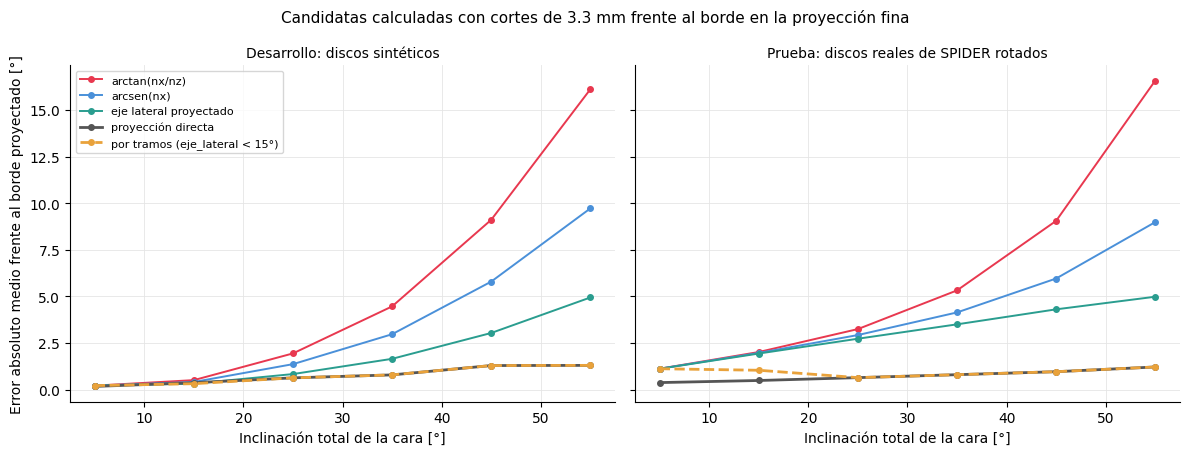

In [ ]:
# 15. Las candidatas en las dos pruebas
errores_prueba = errores_por_tramo(prueba, CANDIDATAS)
filas = []
for nombre, errores in (("desarrollo (sintéticos)", errores_desarrollo), ("prueba (discos reales)", errores_prueba)):
    for medida, tabla in errores.items():
        t = tabla.reset_index().rename(columns={"incl_cara": "tramo_inclinacion"})
        t["tramo_inclinacion"] = t["tramo_inclinacion"].astype(str)
        filas.append(t.assign(prueba=nombre, medida=medida))
resumen_banco = pd.concat(filas, ignore_index=True)
resumen_banco.to_csv(DIR_SALIDA / "resumen_banco_formula.csv", index=False)
for medida in ("eam", "sesgo", "p90"):
    print(f"\n{medida} frente a la referencia (prueba, discos reales)")
    display(errores_prueba[medida].round(2))
total = pd.DataFrame({nombre: {c: np.mean(np.abs(df[c] - df["referencia"])) for c in CANDIDATAS}
                      for nombre, df in (("desarrollo", desarrollo), ("prueba", prueba))})
print("\nError absoluto medio en todas las caras:")
display(total.round(2))
for nombre, df in (("desarrollo", desarrollo), ("prueba", prueba)):
    plano = df[df["inclinacion"] == 0]
    print(f"{nombre}: con el disco sin inclinar, la referencia debería valer 0°; su valor absoluto medio es "
          f"{plano['referencia'].abs().mean():.2f}° (p90 {plano['referencia'].abs().quantile(0.9):.2f}°), "
          f"y el de arctan(nx/nz), {plano['arctan'].abs().mean():.2f}°")

colores = {"arctan": "#e8384f", "arcsen": "#4a90d9", "eje_lateral": "#2a9d8f", "proyeccion": "#555555", "tramos": "#e9a23b"}
etiquetas = {"arctan": "arctan(nx/nz)", "arcsen": "arcsen(nx)", "eje_lateral": "eje lateral proyectado",
             "proyeccion": "proyección directa", "tramos": f"por tramos ({REGLA_TRAMOS['debajo']} < {REGLA_TRAMOS['umbral']}°)"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (nombre, errores) in zip(axes, (("Desarrollo: discos sintéticos", errores_desarrollo),
                                        ("Prueba: discos reales de SPIDER rotados", errores_prueba))):
    t = errores["eam"]
    centros = [(iv.left + min(iv.right, 60)) / 2 for iv in t.index]
    for c in CANDIDATAS:
        ax.plot(centros, t[c], marker="o", ms=4, lw=2 if c in ("proyeccion", "tramos") else 1.4, color=colores[c],
                ls="--" if c == "tramos" else "-", label=etiquetas[c])
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel("Inclinación total de la cara [°]")
    ejes_limpios(ax)
axes[0].set_ylabel("Error absoluto medio frente al borde proyectado [°]")
axes[0].legend(fontsize=8)
fig.suptitle(f"Candidatas calculadas con cortes de {GROSOR_SIMULADO_MM} mm frente al borde en la proyección fina", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_banco_formula.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar las tablas y la gráfica.** La celda 13 muestra la regla por tramos elegida con el desarrollo y, para cada tramo de inclinación de la cara, el error absoluto medio (`eam`), el sesgo y el percentil 90 del error de cada candidata frente a la referencia, en los discos sintéticos. La celda 15 muestra lo mismo para los discos reales de la prueba y el error absoluto medio de cada candidata en todas las caras. En la gráfica, cada línea es una candidata, y cuanto más baja, más se acerca a lo que se ve en la proyección. Todas las candidatas se calculan sobre la versión con cortes de 3,3 mm.

**Resultados.** En el desarrollo, con discos sintéticos, las tres fórmulas de la normal y la proyección directa coinciden por debajo de 20° de inclinación, con errores medios de 0,2° a 0,5°. Por encima se separan. Entre 40° y 50°, $\arctan(n_x/n_z)$ se pasa en promedio 9,1°, $\arcsin(n_x)$ 5,8° y el eje lateral proyectado 3,0°, mientras que la proyección directa se queda en 1,3°, sin sesgo. El orden de las fórmulas es el mismo en todos los tramos, con el eje lateral por delante de $\arcsin(n_x)$ y esta por delante de $\arctan(n_x/n_z)$. Ninguna fórmula de la normal elimina el sesgo, porque el borde proyectado depende también del grosor y de la profundidad del disco, que la normal no contiene. Con estos datos, la regla por tramos que se elige usa el eje lateral por debajo de 15° y la proyección directa por encima.

La ventaja aparente de la proyección directa debe interpretarse con cautela, porque la referencia también es un borde proyectado, así que la proyección directa mide lo mismo que la referencia, solo que con cortes más gruesos. Eso solo es una ventaja si el borde proyectado sigue de verdad la orientación de la cara, cosa que en un disco sintético, plano y regular, se cumple por construcción. La prueba con discos reales sirve justo para comprobarlo, y la última línea de la celda 15 dice cuánto se aparta la referencia de 0° cuando el disco real no está inclinado.

Con 1048 discos reales y 58 688 caras, el orden de las fórmulas se mantiene. En todas las caras, el error absoluto medio es de 6,55° con $\arctan(n_x/n_z)$, 4,28° con $\arcsin(n_x)$ y 3,07° con el eje lateral, y la diferencia crece con la inclinación. Entre 40° y 50°, por ejemplo, es de 9,1°, 6,0° y 4,3°. La proyección directa vuelve a quedar muy por debajo (0,75°), y la regla por tramos, en 0,99°.

Sin embargo, la última línea de la celda 15 pone de manifiesto una limitación importante de esta prueba. Con el disco real sin inclinar, la referencia vale en promedio 1,13° (p90 2,38°) en lugar de 0°, mientras que $\arctan(n_x/n_z)$ vale 0,41°. Esto significa que el borde proyectado de un disco real no sigue solo la orientación de su cara, sino que también recoge su forma, como los abultamientos o la diferencia de altura entre un lado y otro. Por eso la proyección directa sale tan bien aquí, ya que mide esa misma forma. Esta prueba no puede decir, entonces, si la proyección directa sigue mejor la orientación de la cara. Eso se ve en la celda 17, con la reproducibilidad en datos reales.

In [ ]:
# 16. Proyección directa en todos los discos de SPIDER: máscaras manuales únicas y máscaras automáticas
DIR_AUTO = DIR_PRL / "content" / "datos" / "AutoSegments"
FUENTES = {"manual": (DIR_LOCAL, unicas),
           "tss": (DIR_AUTO / "tss" / "convencion_spider", sorted(planos_tss["serie"].unique())),
           "iis": (DIR_AUTO / "iis" / "convencion_spider", sorted(planos_iis["serie"].unique()))}

for fuente, (carpeta, series) in FUENTES.items():
    csv = DIR_SALIDA / f"proyeccion_por_disco_{fuente}.csv"
    hechas = set(pd.read_csv(csv, dtype={"serie": str})["serie"]) if csv.exists() else set()
    pendientes = [s for s in series if s not in hechas]
    print(f"{fuente}: {len(series) - len(pendientes)} hechas, {len(pendientes)} pendientes")
    t0 = time.time()
    for k, s in enumerate(pendientes, 1):
        ruta = carpeta / f"{s}.mha"
        if not ruta.exists():
            print("  falta", ruta)
            continue
        m = espacio_script(ruta)
        filas = []
        for disco in sorted(int(l) for l in np.unique(m) if l > 200):
            b = bordes_proyectados(m == disco)
            filas += [{"serie": s, "disco": disco, "cara": cara, "proyeccion": b[cara]} for cara in ("superior", "inferior")]
        pd.DataFrame(filas).to_csv(csv, mode="a", header=not csv.exists(), index=False)
        if k % 50 == 0:
            print(f"  [{k}/{len(pendientes)}] {(time.time() - t0) / 60:.1f} min")
print("Listo.")

manual: 0 hechas, 340 pendientes
  [50/340] 2.5 min
  [100/340] 5.3 min
  [150/340] 8.2 min
  [200/340] 10.8 min
  [250/340] 13.2 min
  [300/340] 15.8 min
tss: 0 hechas, 447 pendientes
  [50/447] 3.1 min
  [100/447] 6.7 min
  [150/447] 10.1 min
  [200/447] 13.7 min
  [250/447] 17.1 min
  [300/447] 20.2 min
  [350/447] 23.3 min
  [400/447] 26.6 min
iis: 0 hechas, 447 pendientes
  [50/447] 3.1 min
  [100/447] 6.7 min
  [150/447] 10.1 min
  [200/447] 13.7 min
  [250/447] 17.1 min
  [300/447] 20.3 min
  [350/447] 23.4 min
  [400/447] 26.6 min
Listo.


Control de signo y escala: Spearman entre la proyección directa y arctan(nx/nz) en las caras manuales 0.80; caras sin proyección: 0


,media,mediana,dif_media_vs_arctan,mascaras_mas_de_2_vs_arctan
arctan,8.03,5.93,0.00,0.0
arcsen,7.65,5.64,-0.38,12.0
eje_lateral,7.39,5.40,-0.64,23.0
proyeccion,9.34,7.53,1.31,194.0
tramos,8.11,6.36,0.08,105.0


Algunas columnas:
              arctan  arcsen  eje_lateral  proyeccion  tramos
serie                                                        
162_t1          26.6    19.4         14.3        11.1     8.9
162_t2_SPACE    28.7    21.0         15.5        12.5     9.8
65_t1           15.5    13.3         12.4        29.4    27.0
1_t1            45.5    45.3         45.1        42.4    42.4
186_t1          41.5    41.3         41.1        40.7    40.7
35_t2            7.6     6.3          5.2        26.9    26.1


,comparacion,candidata,n,sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs
0,TotalSpineSeg frente a manual,arctan,447,0.03,-2.17,2.23,0.61,1.68,6.58
1,TotalSpineSeg frente a manual,arcsen,447,0.03,-1.95,2.02,0.57,1.56,5.07
2,TotalSpineSeg frente a manual,eje_lateral,447,0.03,-1.83,1.88,0.53,1.44,4.57
3,TotalSpineSeg frente a manual,proyeccion,447,-0.34,-5.72,5.05,1.49,4.15,14.81
4,TotalSpineSeg frente a manual,tramos,447,-0.28,-4.65,4.09,0.86,2.93,16.01
5,SPIDER-Baseline-IIS frente a manual,arctan,445,-0.07,-6.50,6.36,0.44,1.55,66.13
6,SPIDER-Baseline-IIS frente a manual,arcsen,445,-0.19,-1.90,1.52,0.42,1.41,5.23
7,SPIDER-Baseline-IIS frente a manual,eje_lateral,445,-0.19,-1.82,1.43,0.40,1.38,5.15
8,SPIDER-Baseline-IIS frente a manual,proyeccion,445,-0.55,-5.90,4.79,1.26,3.98,17.43
9,SPIDER-Baseline-IIS frente a manual,tramos,445,-0.35,-4.33,3.62,0.70,2.61,10.09


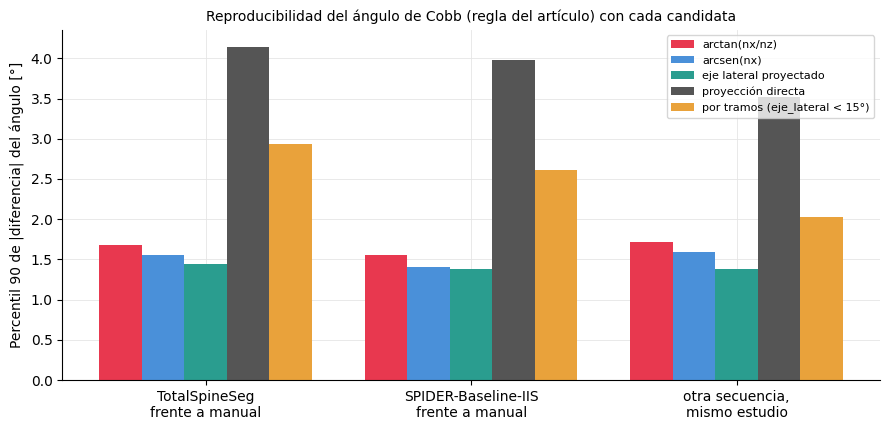

In [ ]:
# 17. Cómo se comporta cada candidata en SPIDER, donde no hay referencia
def caras_con_candidatas(planos, fuente):
    "Las cinco candidatas para cada cara de disco de una fuente (manual, tss o iis)."
    proy = (leer(DIR_SALIDA / f"proyeccion_por_disco_{fuente}.csv")
            .drop_duplicates(["serie", "disco", "cara"], keep="last"))
    if fuente == "manual":   # las series cuya máscara es idéntica a otra toman la proyección de su máscara única
        representante = {s: u for u in unicas for s in huella.index[huella == huella[u]]}
        proy = pd.concat([proy[proy["serie"] == u].assign(serie=s) for s, u in representante.items()], ignore_index=True)
    df = planos.merge(proy, on=["serie", "disco", "cara"], how="left")
    n = df[["nx", "ny", "nz"]].to_numpy(dtype=float)
    n /= np.linalg.norm(n, axis=1, keepdims=True)
    for k, v in formulas_de(n[:, 0], n[:, 1], n[:, 2]).items():
        df[k] = v
    df["incl_cara"] = inclinacion_total(n[:, 2])
    df["tramos"] = aplicar_tramos(df, **REGLA_TRAMOS)
    return df

caras = {"manual": caras_con_candidatas(planos_disco, "manual"),
         "tss": caras_con_candidatas(planos_tss, "tss"), "iis": caras_con_candidatas(planos_iis, "iis")}
cm = caras["manual"][caras["manual"]["serie"].isin(unicas)]
print(f"Control de signo y escala: Spearman entre la proyección directa y arctan(nx/nz) en las caras manuales "
      f"{cm['proyeccion'].corr(cm['arctan'], method='spearman'):.2f}; caras sin proyección: {cm['proyeccion'].isna().sum()}")

def cobb_por_candidata(df):
    filas = []
    for s, g in df.groupby("serie"):
        fila = {"serie": s}
        for c in CANDIDATAS:
            tabla = g.pivot(index="disco", columns="cara", values=c)
            fila[c] = regla_articulo(tabla)[0] if {"superior", "inferior"} <= set(tabla.columns) and len(tabla) >= 2 else np.nan
        filas.append(fila)
    return pd.DataFrame(filas).set_index("serie")

cobb_cand = {f: cobb_por_candidata(df) for f, df in caras.items()}
for f, t in cobb_cand.items():
    t.reset_index().to_csv(DIR_SALIDA / f"cobb_por_candidata_{f}.csv", index=False)

# a) Cuánto cambia el ángulo en las 340 máscaras manuales únicas
manual = cobb_cand["manual"].loc[unicas]
cambio = pd.DataFrame({c: {"media": manual[c].mean(), "mediana": manual[c].median(),
                           "dif_media_vs_arctan": (manual[c] - manual["arctan"]).mean(),
                           "mascaras_mas_de_2_vs_arctan": int(((manual[c] - manual["arctan"]).abs() > 2).sum())}
                       for c in CANDIDATAS}).T
display(cambio.round(2))
print("Algunas columnas:")
print(manual.loc[["162_t1", "162_t2_SPACE", "65_t1", "1_t1", "186_t1", "35_t2"], CANDIDATAS].round(1).to_string())

# b) Reproducibilidad: misma columna, otra segmentación o la misma secuencia con otra máscara
filas = []
for seg in ("tss", "iis"):
    auto = cobb_cand[seg]
    base = cobb_cand["manual"].reindex(auto.index)
    for c in CANDIDATAS:
        d = pd.DataFrame({"estudio": auto.index.map(estudio_de), "dif": auto[c] - base[c]})
        filas.append({"comparacion": f"{NOMBRES[seg]} frente a manual", "candidata": c, **bland_altman(d, "dif")})
pares = parejas[["estudio", "serie_1", "serie_2"]]
for c in CANDIDATAS:
    d = pd.DataFrame({"estudio": pares["estudio"],
                      "dif": cobb_cand["manual"].reindex(pares["serie_1"])[c].to_numpy()
                             - cobb_cand["manual"].reindex(pares["serie_2"])[c].to_numpy()})
    filas.append({"comparacion": "otra secuencia del mismo estudio (máscaras manuales distintas)", "candidata": c,
                  **bland_altman(d, "dif")})
reproducibilidad = pd.DataFrame(filas)
reproducibilidad.to_csv(DIR_SALIDA / "reproducibilidad_por_candidata.csv", index=False)
display(reproducibilidad[["comparacion", "candidata", "n", "sesgo", "lim_inf", "lim_sup", "mediana_abs", "p90_abs", "max_abs"]].round(2))

fig, ax = plt.subplots(figsize=(9, 4.4))
comparaciones = reproducibilidad["comparacion"].unique()
ancho = 0.8 / len(CANDIDATAS)
for j, c in enumerate(CANDIDATAS):
    vals = [reproducibilidad.query("comparacion == @k and candidata == @c")["p90_abs"].iloc[0] for k in comparaciones]
    ax.bar(np.arange(len(comparaciones)) + j * ancho, vals, width=ancho, color=colores[c], label=etiquetas[c])
ax.set_xticks(np.arange(len(comparaciones)) + 0.4 - ancho / 2,
              ["TotalSpineSeg\nfrente a manual", "SPIDER-Baseline-IIS\nfrente a manual", "otra secuencia,\nmismo estudio"])
ax.set_ylabel("Percentil 90 de |diferencia| del ángulo [°]")
ax.set_title("Reproducibilidad del ángulo de Cobb (regla del artículo) con cada candidata", fontsize=10)
ax.legend(fontsize=8)
ejes_limpios(ax)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_reproducibilidad_por_candidata.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar los resultados.** La línea de control comprueba que la proyección directa en las máscaras reales tiene el mismo signo y una escala parecida a la fórmula del script. La primera tabla da, para cada candidata, la media y la mediana del ángulo de Cobb (regla del artículo) en las 340 máscaras manuales únicas, cuánto cambia frente a $\arctan(n_x/n_z)$ y en cuántas máscaras el cambio pasa de 2°, y debajo se muestran algunas columnas conocidas. La segunda tabla mide la reproducibilidad, es decir, la diferencia del ángulo entre la máscara automática y la manual de la misma serie, y entre las máscaras manuales distintas de un mismo estudio, con su sesgo, límites de acuerdo, mediana, percentil 90 y máximo. La gráfica resume el percentil 90 de esas diferencias, y cuanto más baja la barra, más estable es la candidata frente a cambios de segmentación.

**Resultados.** La proyección directa tiene el mismo signo que la fórmula del script y se correlaciona con ella (Spearman 0,80), pero en las máscaras reales se comporta mal. Sube el ángulo medio de 8,03° a 9,34° y lo cambia más de 2° en 194 de las 340 máscaras, y lo hace en las dos direcciones, porque en el estudio 162 baja a 11,1° y 12,5°, mientras que en `65_t1` y `35_t2` sube a 29,4° y 26,9°. Además, es mucho menos reproducible. Entre TotalSpineSeg y la máscara manual, sus límites de acuerdo van de −5,7° a 5,1° (p90 de 4,2°), frente a −2,2° y 2,2° con $\arctan(n_x/n_z)$, y entre secuencias del mismo estudio su p90 es de 3,5°. La regla por tramos hereda ese ruido en las caras inclinadas (p90 entre 2,0° y 2,9°). Como el ángulo de Cobb es el máximo entre muchos pares, el ruido de la forma de cada disco se acumula en él.

Las tres fórmulas de la normal, en cambio, mantienen el ángulo casi igual (las medias van de 7,39° a 8,03°) y son más reproducibles cuanto más se acercan al borde proyectado. Con TotalSpineSeg, los límites de acuerdo son de ±2,2° con $\arctan(n_x/n_z)$, ±2,0° con $\arcsin(n_x)$ y ±1,85° con el eje lateral, y entre secuencias del mismo estudio el p90 baja de 1,72° a 1,59° y 1,38°. Con SPIDER-Baseline-IIS pasa lo mismo, y además $\arcsin(n_x)$ y el eje lateral no se disparan en el fallo de `167_t1` (diferencia máxima de 5,2° frente a 66,1° con $\arctan(n_x/n_z)$), porque no dividen por $n_z$, que en ese plano casi vertical vale casi 0.

En conjunto, el eje lateral proyectado es la mejor candidata entre las evaluadas con los datos disponibles, ya que es la fórmula basada en la normal que más se aproxima al borde proyectado en ambas pruebas y la que muestra mayor reproducibilidad en SPIDER. No obstante, su ventaja frente a $\arcsin(n_x)$ es pequeña. La proyección directa y la regla por tramos se descartan, porque solo se acercan al borde proyectado en la medida en que miden lo mismo que él, y en datos reales son más ruidosas. Por ahora no hay otro modelo que mejore las caras muy inclinadas, pero sí se puede marcar como de baja confianza las caras con más de unos 30° de inclinación, que es donde todas las candidatas se separan del borde proyectado.

Siguiendo el criterio de empezar con la candidata que mejor resulte, aunque sea por poco, desde el cuaderno 08 la fórmula principal es el eje lateral proyectado, y a su lado se reporta $\arctan(n_x/n_z)$ como referencia del método publicado. $\arcsin(n_x)$ deja de reportarse, aunque sus resultados quedan registrados en este cuaderno. El eje lateral es una propuesta de este proyecto, no parte del método publicado, y no está validado frente a mediciones de especialistas.

## Cuaderno 04 · El grosor de corte con la regla correcta

Todas las cifras del cuaderno 04 se calcularon con la regla del script. Las que describen cada cara por separado, como el factor *k* con el que el ángulo coronal de una cara se acerca a 0° al engrosar, no dependen de la regla. Las que describen el ángulo de Cobb sí dependen de ella, como el cambio con cada grosor, los cambios de par y el acuerdo entre la T2 SPACE y la serie estándar. El cuaderno 04 guardó los planos de cada cara en cada corrida del experimento, así que la celda 18 puede recalcular esas cifras con la regla del artículo sin volver a correr el script. Primero comprueba que la regla del script reproduce el ángulo que registró el cuaderno 04.

In [ ]:
# 18. El experimento de grosor y la comparación T2 SPACE frente a serie estándar, con la regla del artículo
filas = []
for (s, condicion), g in planos_04.groupby(["serie", "condicion"]):
    tabla = tabla_de_caras(g)
    ar, sc = regla_articulo(tabla), regla_script(tabla)
    f0 = g.iloc[0]
    filas.append({"serie": s, "condicion": condicion, "metodo": f0["metodo"], "grosor_mm": f0["grosor_mm"],
                  "desfase": f0["desfase"], "cobb_articulo": ar[0], "par_articulo": (ar[1], ar[2]),
                  "cobb_script": sc[0], "angulo_script_04": f0["angulo_script"]})
grosor = pd.DataFrame(filas)
print(f"Control: regla del script frente al ángulo registrado en el cuaderno 04, diferencia máxima "
      f"{(grosor['cobb_script'] - grosor['angulo_script_04']).abs().max():.1e}° en {len(grosor)} corridas")
base = grosor[grosor["condicion"] == "base"].set_index("serie")
grosor = grosor[grosor["condicion"] != "base"].copy()
for regla in ("articulo", "script"):
    grosor[f"dif_{regla}"] = grosor[f"cobb_{regla}"] - base.loc[grosor["serie"], f"cobb_{regla}"].to_numpy()
grosor["cambio_relativo_pct_articulo"] = 100 * grosor["dif_articulo"] / base.loc[grosor["serie"], "cobb_articulo"].to_numpy()
grosor["cambia_par_articulo"] = [p != base.loc[s, "par_articulo"] for s, p in zip(grosor["serie"], grosor["par_articulo"])]
grosor.drop(columns="par_articulo").to_csv(DIR_SALIDA / "grosor_con_regla_del_articulo.csv", index=False)

resumen_grosor = (grosor.groupby(["grosor_mm", "metodo"])
                  .agg(corridas=("serie", "size"), mediana_dif_script=("dif_script", "median"),
                       mediana_dif_articulo=("dif_articulo", "median"),
                       mediana_relativa_pct_articulo=("cambio_relativo_pct_articulo", "median"),
                       p90_abs_articulo=("dif_articulo", lambda x: x.abs().quantile(0.9)),
                       max_abs_articulo=("dif_articulo", lambda x: x.abs().max()),
                       cambia_par_articulo=("cambia_par_articulo", "sum")))
resumen_grosor.to_csv(DIR_SALIDA / "resumen_grosor_con_regla_del_articulo.csv")
display(resumen_grosor.round(2))

# T2 SPACE frente a la serie estándar del mismo estudio (las 59 comparaciones del cuaderno 04)
def cobb_articulo_de(serie):
    return regla_articulo(tabla_de_caras(planos_disco[planos_disco["serie"] == serie]))[0]
comp = comparaciones_04.copy()
comp["serie_space"] = comp["estudio"].astype(str) + "_t2_SPACE"
comp["dif_articulo"] = [cobb_articulo_de(e) - cobb_articulo_de(sp) for e, sp in zip(comp["serie_estandar"], comp["serie_space"])]
comp["dif_script"] = comp["dif_estandar_menos_space"]
comp.to_csv(DIR_SALIDA / "space_frente_a_estandar_con_regla_del_articulo.csv", index=False)
filas = []
for conjunto, g in (("todas las comparaciones", comp), ("misma cobertura", comp[comp["misma_cobertura"]])):
    for regla in ("script", "articulo"):
        filas.append({"conjunto": conjunto, "regla": regla, **bland_altman(g, f"dif_{regla}")})
space_estandar = pd.DataFrame(filas)
space_estandar.to_csv(DIR_SALIDA / "resumen_space_frente_a_estandar.csv", index=False)
display(space_estandar.round(2))

Control: regla del script frente al ángulo registrado en el cuaderno 04, diferencia máxima 7.1e-15° en 533 corridas


corridas  mediana_dif_script  mediana_dif_articulo  \
grosor_mm metodo                                                            
3.3       mayoritaria       123               -0.22                 -0.25   
          vecino            123               -0.23                 -0.24   
4.4       mayoritaria       123               -0.42                 -0.38   
          vecino            123               -0.39                 -0.37   

                       mediana_relativa_pct_articulo  p90_abs_articulo  \
grosor_mm metodo                                                         
3.3       mayoritaria                          -3.25              0.90   
          vecino                               -3.16              0.88   
4.4       mayoritaria                          -5.11              1.07   
          vecino                               -4.78              1.00   

                       max_abs_articulo  cambia_par_articulo  
grosor_mm metodo                                              
3.3       mayoritaria              1.74                   15  
          vecino                   1.72                   16  
4.4       mayoritaria              2.45                   25  
          vecino                   2.31                   29

,conjunto,regla,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs
0,todas las comparaciones,script,59,39,-0.32,-0.70 a 0.09,-3.09,2.44,0.56,2.43,6.84
1,todas las comparaciones,articulo,59,39,-0.50,-0.84 a -0.19,-2.62,1.63,0.60,1.88,3.66
2,misma cobertura,script,53,38,-0.51,-0.84 a -0.19,-2.59,1.58,0.53,2.39,3.33
3,misma cobertura,articulo,53,38,-0.54,-0.90 a -0.19,-2.68,1.60,0.65,2.03,3.66


**Cómo interpretar las tablas.** La línea de control compara la regla del script, reconstruida aquí, con el ángulo que registró el cuaderno 04 en cada una de sus corridas. La primera tabla resume, para cada grosor simulado y método de engrosamiento, cuánto cambia el ángulo frente a la máscara T2 SPACE original con las dos reglas, con la mediana del cambio en grados, la mediana del cambio relativo, el percentil 90 y el máximo del cambio absoluto y cuántas corridas cambian de par con la regla del artículo. La segunda tabla repite el acuerdo entre la serie estándar y la T2 SPACE del mismo estudio (estándar menos SPACE) con las dos reglas, con todas las comparaciones y solo con las que tienen los mismos discos.

**Resultados.** La regla del script reproduce exactamente el ángulo de las 533 corridas del cuaderno 04, así que el recálculo parte de los mismos planos. Con la regla del artículo, las cifras del experimento casi no cambian. Al simular cortes de 3,3 mm el ángulo baja una mediana de 0,24° a 0,25° (con el script, 0,22° a 0,23°), y con 4,4 mm, de 0,37° a 0,38° (con el script, 0,39° a 0,42°). En términos relativos son −3,2 % con 3,3 mm y entre −4,8 % y −5,1 % con 4,4 mm, y el cambio máximo es de 2,45°. Los cambios de par también son parecidos, entre 15 y 29 corridas de 123, según el grosor y el método.

La comparación entre la T2 SPACE y la serie estándar del mismo estudio sí cambia algo. Con la regla del artículo, los límites de acuerdo se estrechan (de −3,09° y 2,44° a −2,62° y 1,63°) y la diferencia máxima baja de 6,84° a 3,66°, sobre todo porque desaparece el caso de `35_t2`. El sesgo, en cambio, pasa de −0,32° a −0,50°, y su intervalo de confianza (−0,84° a −0,19°) ya no incluye el cero, lo que indica que la serie estándar da un ángulo algo menor que la T2 SPACE, en el mismo sentido que predice el grosor de corte (−0,28° en el cuaderno 04). Con la misma cobertura, las dos reglas dan casi lo mismo (sesgos de −0,51° y −0,54°).

Por lo tanto, la conclusión del cuaderno 04 se sostiene con la regla correcta, ya que el grosor de corte produce una subestimación pequeña y proporcional, y no justifica descartar las series estándar.

## Cuaderno 05 · SPIDER-Baseline-IIS en las series de entrenamiento frente a las de validación

SPIDER-Baseline-IIS se desarrolló con las particiones de entrenamiento y validación de SPIDER, y el conjunto de prueba es aparte y no es público. Las 447 series públicas pertenecen a esas dos particiones, así que ninguna es del todo nueva para el modelo. La celda 19 compara, con los resultados del cuaderno 05, el acuerdo con la máscara manual en las series de entrenamiento y en las de validación. Si el modelo estuviera ajustado de más a sus datos de entrenamiento, cabría esperar un acuerdo mejor en ellas.

TotalSpineSeg se incluye como referencia. También usó datos de SPIDER, pero sus autores no indican qué partición, así que la comparación no se puede interpretar de la misma forma.

,segmentador,particion,series,estudios,mediana_abs,ic95_mediana_abs,p90_abs,sesgo,lim_inf,lim_sup,max_abs,con_alguna_marca_pct,posible_disco_omitido_pct,mismo_par_pct
0,SPIDER-Baseline-IIS,training,359.0,179.0,0.46,0.38 a 0.53,1.58,-0.04,-7.14,7.06,66.13,17.27,3.62,64.90
1,SPIDER-Baseline-IIS,validation,86.0,39.0,0.36,0.28 a 0.61,1.43,-0.18,-2.00,1.64,3.93,27.91,9.30,63.95
2,SPIDER-Baseline-IIS,validación − entrenamiento,NaN,NaN,-0.10,-0.21 a 0.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TotalSpineSeg,training,360.0,179.0,0.60,0.50 a 0.68,1.74,0.02,-2.18,2.23,6.58,16.39,0.00,57.78
4,TotalSpineSeg,validation,87.0,39.0,0.65,0.42 a 0.92,1.59,0.05,-2.14,2.24,4.68,16.09,0.00,55.17
5,TotalSpineSeg,validación − entrenamiento,NaN,NaN,0.06,-0.21 a 0.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


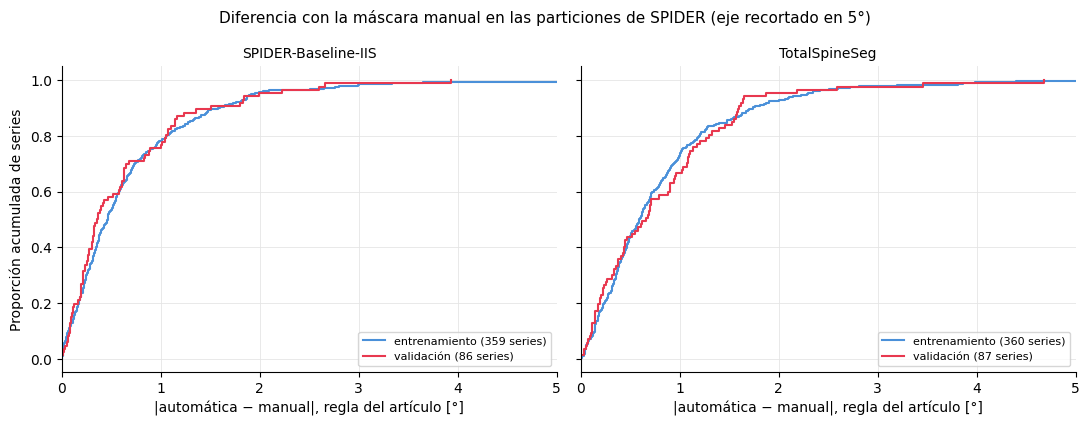

In [ ]:
# 19. Acuerdo con la máscara manual en las series de entrenamiento y de validación de SPIDER (cuaderno 05)
COL = "dif_articulo_completo"       # regla del artículo, todos los discos

def mediana_abs_bootstrap(g, rng):
    "Mediana de |diferencia| remuestreando estudios completos."
    grupos = [x.abs().values for _, x in g.groupby("estudio")[COL]]
    return np.array([np.median(np.concatenate([grupos[k] for k in rng.integers(0, len(grupos), len(grupos))]))
                     for _ in range(B_BOOTSTRAP)])

filas = []
for seg, gs in comparacion_05.dropna(subset=[COL]).groupby("segmentador"):
    rng = np.random.default_rng(SEMILLA)
    boot = {}
    for subset, g in gs.groupby("subset"):
        boot[subset] = mediana_abs_bootstrap(g, rng)
        ba = bland_altman(g, COL)
        filas.append({"segmentador": NOMBRES.get(seg, seg), "particion": subset, "series": len(g),
                      "estudios": g["estudio"].nunique(), "mediana_abs": g[COL].abs().median(),
                      "ic95_mediana_abs": f"{np.percentile(boot[subset], 2.5):.2f} a {np.percentile(boot[subset], 97.5):.2f}",
                      "p90_abs": g[COL].abs().quantile(0.9), "sesgo": ba["sesgo"], "lim_inf": ba["lim_inf"],
                      "lim_sup": ba["lim_sup"], "max_abs": g[COL].abs().max(),
                      "con_alguna_marca_pct": 100 * g["alguna_marca"].mean(),
                      "posible_disco_omitido_pct": 100 * g["posible_disco_omitido"].mean(),
                      "mismo_par_pct": 100 * g["mismo_par_articulo_completo"].mean()})
    d = boot["validation"] - boot["training"]
    filas.append({"segmentador": NOMBRES.get(seg, seg), "particion": "validación − entrenamiento",
                  "mediana_abs": np.median(gs.loc[gs["subset"] == "validation", COL].abs())
                                 - np.median(gs.loc[gs["subset"] == "training", COL].abs()),
                  "ic95_mediana_abs": f"{np.percentile(d, 2.5):.2f} a {np.percentile(d, 97.5):.2f}"})
entrenamiento_validacion = pd.DataFrame(filas)
entrenamiento_validacion.to_csv(DIR_SALIDA / "entrenamiento_frente_a_validacion.csv", index=False)
display(entrenamiento_validacion.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, (seg, gs) in zip(axes, comparacion_05.dropna(subset=[COL]).groupby("segmentador")):
    for subset, color, nombre in (("training", "#4a90d9", "entrenamiento"), ("validation", "#e8384f", "validación")):
        x = np.sort(gs.loc[gs["subset"] == subset, COL].abs().to_numpy())
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=color, label=f"{nombre} ({len(x)} series)")
    ax.set_xlim(0, 5)
    ax.set_title(NOMBRES.get(seg, seg), fontsize=10)
    ax.set_xlabel("|automática − manual|, regla del artículo [°]")
    ax.legend(fontsize=8, loc="lower right")
    ejes_limpios(ax)
axes[0].set_ylabel("Proporción acumulada de series")
fig.suptitle("Diferencia con la máscara manual en las particiones de SPIDER (eje recortado en 5°)", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_entrenamiento_frente_a_validacion.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar la tabla y la gráfica.** Para cada segmentador hay una fila por partición de SPIDER y una tercera con la diferencia entre las dos. Se muestran el número de series y de estudios, la mediana de la diferencia absoluta con su intervalo de confianza (*bootstrap* por estudio), el percentil 90, el sesgo y los límites de acuerdo, la diferencia máxima, el porcentaje de series con alguna marca de calidad o con un posible disco omitido y el porcentaje en el que coincide el par elegido. En la fila de la diferencia, un valor negativo significa que el acuerdo es mejor en validación. La gráfica muestra, para cada partición, la proporción de series cuya diferencia no supera cada valor del eje horizontal.

**Resultados.** Con SPIDER-Baseline-IIS, el acuerdo no es mejor en las series de entrenamiento, ya que la mediana de la diferencia absoluta es de 0,46° en entrenamiento (359 series, 179 estudios) y de 0,36° en validación (86 series, 39 estudios), y el intervalo de la diferencia entre las dos (−0,21° a 0,15°) incluye el cero. Los límites de acuerdo son más amplios en entrenamiento porque ahí está el fallo más grave, `167_t1`. Lo que sí cambia es la frecuencia de las marcas de calidad, mayor en validación (27,9 % frente a 17,3 %, y un posible disco omitido en el 9,3 % frente al 3,6 %), aunque con solo 39 estudios de validación esas proporciones son poco precisas. Con TotalSpineSeg, las dos particiones se comportan de forma parecida (medianas de 0,60° y 0,65°).

Esto no permite concluir que el acuerdo sea igual de bueno con datos nuevos. Las dos particiones se usaron en el desarrollo del modelo y vienen de los mismos hospitales y escáneres. Lo único que se puede decir es que, dentro de SPIDER, no aparece una ventaja clara en las series con las que se entrenó. La prueba que falta es en otro dataset, que es lo que aborda el cuaderno 08.

## Cuadernos 05 y 06 · La dirección de la inclinación y el extremo caudal del estudio 65

En el cuaderno 05, TotalSpineSeg dio en las tres series del estudio 65 entre 4° y 6,6° más que la máscara manual, sin ninguna marca de calidad, y el cuaderno 06 encontró que en ese mismo estudio el platillo inferior de la vértebra 1 tiene una inclinación coronal unos 4° mayor que la cara del disco 201 que lo toca. Quedaron dos preguntas, que son por qué el extremo caudal del 65 cambia tanto según la superficie que se mida y si eso se repite en otras columnas en las que ese disco está muy inclinado.

La clave está en separar la orientación de cada cara en dos números. La **inclinación total** $i$ es el ángulo entre la normal y el eje craneocaudal, es decir, cuánto se aparta la cara de la horizontal. La **dirección** $a$ indica hacia dónde se inclina en el plano axial, y vale 0° si se inclina solo hacia atrás, como en una lordosis pura, y 90° si se inclina solo hacia un lado. Con esas dos variables, la fórmula del script se escribe así.

$$
\tan\theta_{\mathrm{coronal}} = \frac{n_x}{n_z} = \tan i \cdot \sin a
$$

Esto significa que, en una cara poco inclinada, un cambio en la dirección casi no mueve el ángulo coronal, porque $\tan i$ es pequeño. En cambio, en una cara inclinada unos 45°, como la superior del disco 201 en una columna con mucha lordosis, $\tan i \approx 1$, y cada grado de diferencia en la dirección se traduce casi en un grado de ángulo coronal. La celda 20 comprueba esta descomposición en todas las caras y la usa para explicar el estudio 65.

Control: arctan(nx/nz) frente a atan(tan i · sen a), diferencia máxima 7.2e-13°


,segmentador,inclinacion_total_manual,caras,mediana_abs_dif_coronal,p90_abs_dif_coronal,mediana_abs_dif_direccion,mediana_abs_dif_incl,pct_explicado_por_direccion,mediana_abs_dif_arcsen,p90_abs_dif_arcsen
0,TotalSpineSeg,"(0, 10]",3123,0.35,0.96,3.55,0.50,64.29,0.35,0.96
1,TotalSpineSeg,"(10, 20]",2058,0.36,1.06,1.47,0.62,76.27,0.35,1.03
2,TotalSpineSeg,"(20, 30]",594,0.36,1.28,0.84,0.62,83.22,0.33,1.21
3,TotalSpineSeg,"(30, 40]",345,0.39,1.13,0.57,0.66,88.99,0.32,0.92
4,TotalSpineSeg,"(40, 90]",174,0.68,2.27,0.56,0.82,85.13,0.45,1.49
5,SPIDER-Baseline-IIS,"(0, 10]",3074,0.24,0.84,2.60,0.31,68.96,0.24,0.84
6,SPIDER-Baseline-IIS,"(10, 20]",2025,0.26,0.95,1.10,0.38,78.64,0.25,0.91
7,SPIDER-Baseline-IIS,"(20, 30]",590,0.27,1.19,0.62,0.44,82.73,0.25,1.08
8,SPIDER-Baseline-IIS,"(30, 40]",345,0.29,1.13,0.44,0.41,88.76,0.24,0.91
9,SPIDER-Baseline-IIS,"(40, 90]",174,0.41,2.39,0.42,0.49,87.40,0.27,1.48


SPIDER-Baseline-IIS, cara superior del 201 (447 series): Spearman de |diferencia coronal| con tan(i)·|Δ dirección| 0.92, con la inclinación total 0.17; series con más de 3°: 6
TotalSpineSeg, cara superior del 201 (447 series): Spearman de |diferencia coronal| con tan(i)·|Δ dirección| 0.92, con la inclinación total 0.18; series con más de 3°: 9

Cara superior del 201: las series con mayor diferencia
       serie         segmentador  incl_m  direccion_m  direccion_a  dif_direccion  dif_incl  dif_coronal  parte_direccion  parte_inclinacion
       74_t2 SPIDER-Baseline-IIS    39.5          1.4        167.6          166.1      -4.1          7.5              8.9               -1.4
       65_t1       TotalSpineSeg    44.3          7.5         13.8            6.3       0.0          5.9              5.9                0.0
       38_t1 SPIDER-Baseline-IIS    35.5         -1.0          6.8            7.8       1.8          5.9              5.6                0.3
      162_t1       TotalSpineSeg  

,caras,mediana_abs_dif_coronal,p90_abs_dif_coronal,mediana_abs_dif_direccion,mediana_abs_dif_incl
incl_m,,,,,
"(0, 10]",2448,0.36,0.99,4.94,0.85
"(10, 20]",1501,0.34,1.05,1.63,0.95
"(20, 30]",365,0.39,1.35,1.05,1.69
"(30, 40]",110,0.41,1.32,0.72,1.83
"(40, 90]",45,0.68,2.31,0.58,2.46


,serie,superficie,incl,direccion,arctan_nx_nz,arcsen_nx
0,65_t1,"cara superior del 201, manual",44.29,7.46,7.21,5.20
1,65_t1,"cara superior del 201, TotalSpineSeg",44.33,13.78,13.10,9.58
2,65_t1,"cara superior del 201, SPIDER-Baseline-IIS",44.23,10.23,9.81,7.12
3,65_t1,"platillo inferior de V1, manual (cuaderno 06)",40.62,13.53,11.35,8.76
4,65_t2,"cara superior del 201, manual",43.18,10.41,9.63,7.10
5,65_t2,"cara superior del 201, TotalSpineSeg",43.85,14.02,13.10,9.66
6,65_t2,"cara superior del 201, SPIDER-Baseline-IIS",43.92,13.19,12.40,9.11
7,65_t2,"platillo inferior de V1, manual (cuaderno 06)",40.47,14.93,12.40,9.63
8,65_t2_SPACE,"cara superior del 201, manual",43.23,8.92,8.30,6.10
9,65_t2_SPACE,"cara superior del 201, TotalSpineSeg",43.32,13.28,12.22,9.07


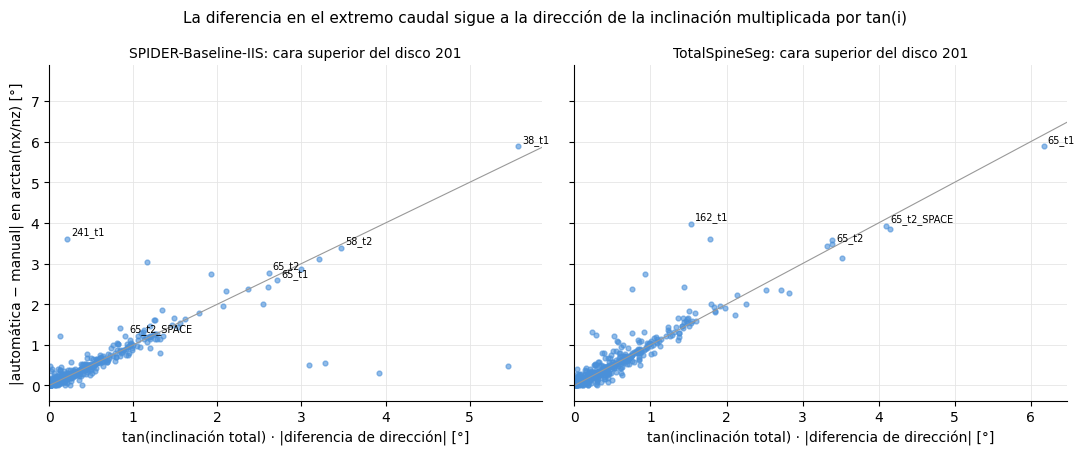

In [ ]:
# 20. Inclinación total y dirección: máscara manual frente a automáticas, y platillo frente a cara de disco
def con_geometria(df):
    "Agrega la inclinación total (incl) y la dirección (direccion) de cada plano a partir de su normal."
    n = df[["nx", "ny", "nz"]].to_numpy(dtype=float)
    n = n / np.linalg.norm(n, axis=1, keepdims=True)
    n = n * np.where(n[:, [2]] < 0, -1, 1)
    df = df.copy()
    df["incl"] = np.degrees(np.arccos(n[:, 2]))
    df["direccion"] = np.degrees(np.arctan2(n[:, 0], -n[:, 1]))
    return df

def coronal(incl, direccion):
    return np.degrees(np.arctan(np.tan(np.radians(incl)) * np.sin(np.radians(direccion))))

manual = con_geometria(planos_disco)
print(f"Control: arctan(nx/nz) frente a atan(tan i · sen a), diferencia máxima "
      f"{(coronal(manual['incl'], manual['direccion']) - manual['angulo_coronal_script']).abs().max():.1e}°")

BINS = [0, 10, 20, 30, 40, 90]
descomp, filas = [], []
for seg, planos_auto in (("tss", planos_tss), ("iis", planos_iis)):
    j = manual.merge(con_geometria(planos_auto), on=["serie", "disco", "cara"], suffixes=("_m", "_a"))
    j["segmentador"] = NOMBRES[seg]
    j["dif_coronal"] = j["angulo_coronal_script_a"] - j["angulo_coronal_script_m"]
    j["dif_arcsen"] = j["arcsen_nx_a"] - j["arcsen_nx_m"]
    j["dif_direccion"] = (j["direccion_a"] - j["direccion_m"] + 180) % 360 - 180
    j["dif_incl"] = j["incl_a"] - j["incl_m"]
    j["parte_direccion"] = coronal(j["incl_m"], j["direccion_a"]) - coronal(j["incl_m"], j["direccion_m"])
    j["parte_inclinacion"] = coronal(j["incl_a"], j["direccion_a"]) - coronal(j["incl_m"], j["direccion_a"])
    j["sensibilidad"] = np.tan(np.radians(j["incl_m"])) * j["dif_direccion"].abs()
    descomp.append(j)
    for tramo, g in j.groupby(pd.cut(j["incl_m"], BINS), observed=True):
        filas.append({"segmentador": NOMBRES[seg], "inclinacion_total_manual": str(tramo), "caras": len(g),
                      "mediana_abs_dif_coronal": g["dif_coronal"].abs().median(),
                      "p90_abs_dif_coronal": g["dif_coronal"].abs().quantile(0.9),
                      "mediana_abs_dif_direccion": g["dif_direccion"].abs().median(),
                      "mediana_abs_dif_incl": g["dif_incl"].abs().median(),
                      "pct_explicado_por_direccion": 100 * (g["parte_direccion"].abs()
                                                            / (g["parte_direccion"].abs() + g["parte_inclinacion"].abs())).median(),
                      "mediana_abs_dif_arcsen": g["dif_arcsen"].abs().median(),
                      "p90_abs_dif_arcsen": g["dif_arcsen"].abs().quantile(0.9)})
descomp = pd.concat(descomp, ignore_index=True)
descomp.to_csv(DIR_SALIDA / "direccion_manual_frente_a_automatica.csv", index=False)
por_inclinacion = pd.DataFrame(filas)
por_inclinacion.to_csv(DIR_SALIDA / "resumen_direccion_por_inclinacion.csv", index=False)
display(por_inclinacion.round(2))

caudal = descomp[(descomp["disco"] == 201) & (descomp["cara"] == "superior")]
for seg, g in caudal.groupby("segmentador"):
    print(f"{seg}, cara superior del 201 ({len(g)} series): Spearman de |diferencia coronal| con tan(i)·|Δ dirección| "
          f"{g['dif_coronal'].abs().corr(g['sensibilidad'], method='spearman'):.2f}, con la inclinación total "
          f"{g['dif_coronal'].abs().corr(g['incl_m'], method='spearman'):.2f}; series con más de 3°: "
          f"{int((g['dif_coronal'].abs() > 3).sum())}")
print("\nCara superior del 201: las series con mayor diferencia")
print(caudal.assign(orden=caudal["dif_coronal"].abs()).sort_values("orden", ascending=False).head(10)
      [["serie", "segmentador", "incl_m", "direccion_m", "direccion_a", "dif_direccion", "dif_incl", "dif_coronal",
        "parte_direccion", "parte_inclinacion"]].round(1).to_string(index=False))

# Platillo frente a la cara del disco que lo toca (cuaderno 06), en las máscaras únicas
plat = con_geometria(platillos_06.dropna(subset=["nx"]))
plat = plat[plat["serie"].isin(unicas) & plat["disco_vecino"].notna()].copy()
plat["disco"] = plat["disco_vecino"].astype(int)
plat["cara"] = np.where(plat["platillo"] == "inferior", "superior", "inferior")   # el platillo inferior toca la cara superior
pc = plat.merge(manual, on=["serie", "disco", "cara"], suffixes=("_p", "_m"))
pc["dif_coronal"] = pc["angulo_coronal"] - pc["angulo_coronal_script"]
pc["dif_direccion"] = (pc["direccion_p"] - pc["direccion_m"] + 180) % 360 - 180
pc["dif_incl"] = pc["incl_p"] - pc["incl_m"]
pc["parte_direccion"] = coronal(pc["incl_m"], pc["direccion_p"]) - coronal(pc["incl_m"], pc["direccion_m"])
pc["parte_inclinacion"] = coronal(pc["incl_p"], pc["direccion_p"]) - coronal(pc["incl_m"], pc["direccion_p"])
pc.to_csv(DIR_SALIDA / "direccion_platillo_frente_a_cara.csv", index=False)
resumen_pc = (pc.groupby(pd.cut(pc["incl_m"], BINS), observed=True)
              .agg(caras=("serie", "size"), mediana_abs_dif_coronal=("dif_coronal", lambda x: x.abs().median()),
                   p90_abs_dif_coronal=("dif_coronal", lambda x: x.abs().quantile(0.9)),
                   mediana_abs_dif_direccion=("dif_direccion", lambda x: x.abs().median()),
                   mediana_abs_dif_incl=("dif_incl", lambda x: x.abs().median())))
display(resumen_pc.round(2))

# El estudio 65, superficie por superficie, en la interfaz entre la vértebra 1 y el disco 201
filas = []
for s in ("65_t1", "65_t2", "65_t2_SPACE"):
    for nombre, df in (("cara superior del 201, manual", manual), ("cara superior del 201, TotalSpineSeg", con_geometria(planos_tss)),
                       ("cara superior del 201, SPIDER-Baseline-IIS", con_geometria(planos_iis))):
        q = df[(df["serie"] == s) & (df["disco"] == 201) & (df["cara"] == "superior")].iloc[0]
        filas.append({"serie": s, "superficie": nombre, "incl": q["incl"], "direccion": q["direccion"],
                      "arctan_nx_nz": q["angulo_coronal_script"], "arcsen_nx": q["arcsen_nx"]})
    q = plat[(plat["serie"] == s) & (plat["vertebra"] == 1) & (plat["platillo"] == "inferior")].iloc[0]
    filas.append({"serie": s, "superficie": "platillo inferior de V1, manual (cuaderno 06)", "incl": q["incl"],
                  "direccion": q["direccion"], "arctan_nx_nz": q["angulo_coronal"],
                  "arcsen_nx": np.degrees(np.arcsin(q["nx"] / np.linalg.norm(q[["nx", "ny", "nz"]].astype(float))))})
estudio_65 = pd.DataFrame(filas)
estudio_65.to_csv(DIR_SALIDA / "estudio_65_por_superficie.csv", index=False)
display(estudio_65.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (seg, g) in zip(axes, caudal.groupby("segmentador")):
    ax.scatter(g["sensibilidad"], g["dif_coronal"].abs(), s=12, alpha=0.6, color="#4a90d9")
    lim = g.loc[g["sensibilidad"] <= 20, "sensibilidad"].max() * 1.05       # más de 20: fallos de segmentación
    visibles = g[g["sensibilidad"] <= lim]
    rotular = set(visibles.loc[visibles["serie"].str.startswith("65_"), "serie"]) | set(
        visibles.assign(o=visibles["dif_coronal"].abs()).nlargest(3, "o")["serie"])
    for s, f in visibles.set_index("serie").loc[sorted(rotular)].iterrows():
        ax.annotate(s, (f["sensibilidad"], abs(f["dif_coronal"])), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.plot([0, lim], [0, lim], color="#999999", lw=0.8)
    ax.set_xlim(0, lim)
    ax.set_xlabel("tan(inclinación total) · |diferencia de dirección| [°]")
    ax.set_title(f"{seg}: cara superior del disco 201", fontsize=10)
    ejes_limpios(ax)
axes[0].set_ylabel("|automática − manual| en arctan(nx/nz) [°]")
fig.suptitle("La diferencia en el extremo caudal sigue a la dirección de la inclinación multiplicada por tan(i)", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_direccion_extremo_caudal.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar las tablas y la gráfica.** La línea de control comprueba que la descomposición reproduce exactamente la fórmula del script. La primera tabla compara cada cara de disco de la máscara automática con la misma cara de la máscara manual, agrupando las caras según su inclinación total en la máscara manual. Para cada grupo se muestran cuántas caras hay, la mediana y el percentil 90 de la diferencia en el ángulo coronal, la mediana de la diferencia en dirección y en inclinación total, qué parte de la diferencia coronal se debe a la dirección (mediana por cara) y, en las dos últimas columnas, la misma diferencia medida con $\arcsin(n_x)$. Después se resume la cara superior del disco 201, que es la del extremo caudal en la regla del artículo, y se listan las series con mayor diferencia. La segunda tabla hace la misma comparación entre cada platillo del cuaderno 06 y la cara de disco que lo toca. La tercera tabla muestra el estudio 65, superficie por superficie. En la gráfica, cada punto es una serie. El eje horizontal es la diferencia de dirección multiplicada por $\tan i$, que es lo que predice la fórmula, y la diagonal marca una coincidencia exacta. Se dejan fuera los puntos con más de 20 en ese eje, que corresponden a fallos de segmentación.

**Resultados.** La descomposición reproduce la fórmula del script con diferencias de redondeo. La primera tabla muestra el patrón esperado. En las caras poco inclinadas, la dirección cambia bastante entre máscaras (mediana de 3,6° con TotalSpineSeg), pero casi no mueve el ángulo coronal, mientras que en las de más de 40° la dirección coincide mejor (0,6°), aunque cada grado pesa casi un grado. Por eso la diferencia coronal crece en esas caras, y el percentil 90 pasa de cerca de 1° a 2,3° con TotalSpineSeg y a 2,4° con SPIDER-Baseline-IIS. En todos los tramos, la mayor parte de la diferencia viene de la dirección y no de la inclinación total (entre el 64 % y el 89 %). Con $\arcsin(n_x)$, el percentil 90 en las caras de más de 40° baja a 1,5°.

En la cara superior del disco 201, la diferencia entre la máscara automática y la manual sigue muy de cerca a $\tan i \cdot |\Delta a|$ (Spearman 0,92 con los dos segmentadores) y casi nada a la inclinación total por sí sola (0,17 y 0,18). Solo 9 series con TotalSpineSeg y 6 con SPIDER-Baseline-IIS pasan de 3°.

El estudio 65 es el ejemplo más claro. Las superficies de la interfaz entre la vértebra 1 y el disco 201 tienen casi la misma inclinación total, entre 40,5° y 44,3°, y difieren sobre todo en la dirección. En `65_t1`, la cara del disco de la máscara manual apunta a 7,5°, la de TotalSpineSeg a 13,8° y el platillo de la propia máscara manual a 13,5°. Con esa inclinación, $\tan i \approx 1$, y esos 6° de dirección se convierten en casi 6° de ángulo coronal. En las tres series del estudio, la que se aparta es la cara del disco manual, ya que la de TotalSpineSeg y el platillo apuntan casi en la misma dirección.

El caso se repite cuando se juntan las dos condiciones, una cara muy inclinada y una diferencia de dirección de varios grados, como en `38_t1` (35,5° de inclinación y entre 4,7° y 7,8° de diferencia de dirección), `156_t1` y `58_t2`. El estudio 162 tiene otro mecanismo, porque su cara está inclinada en parte hacia un lado (dirección de unos 20°), así que pesa la diferencia en la inclinación total, de 3° a 4°. Algunos puntos se apartan de la diagonal por errores de segmentación y no por la geometría, como `74_t2`, en el que SPIDER-Baseline-IIS segmentó un solo disco y la dirección queda invertida (fuera de la gráfica), o `241_t1`, con 30° de diferencia en la inclinación total.

La comparación entre el platillo y la cara de disco del cuaderno 06 (segunda tabla) muestra el mismo patrón, con una diferencia coronal pequeña hasta los 40° de inclinación que crece por encima, donde además difiere más la inclinación total (mediana de 2,5°), porque el platillo y la cara del disco se ajustan sobre puntos distintos.

Por lo tanto, la respuesta a las dos preguntas es la misma. En una cara inclinada unos 45°, el ángulo coronal depende casi grado por grado de hacia dónde apunta la inclinación en el plano axial, un detalle que cambia con la segmentación y con la superficie que se mida. No es un error de un segmentador ni del ajuste de los platillos, sino una sensibilidad del ángulo coronal en las caras lordóticas, relacionada con la limitación de la inclinación sagital que mencionó Jasper van der Graaf en el issue.

## Cuaderno 06 · La distancia de contacto de los platillos

El cuaderno 06 exigió que cada punto del platillo estuviera a menos de 3 mm del disco que lo toca, y esa condición cambió el ángulo por platillos en 1,25° de media. El umbral se eligió en ese cuaderno y quedó la pregunta de cuánto cambiarían los resultados con 2 o 4 mm.

Las celdas 21 a 23 responden con el mismo método. La celda 21 copia las funciones del cuaderno 06 sin cambiar su lógica. La única diferencia es que la superficie de cada cuerpo vertebral se calcula una sola vez y se reutiliza para las tres distancias, en lugar de recalcularla en cada pasada. La celda 22 corre las 340 máscaras con 2, 3 y 4 mm y la celda 23 compara los tres resultados. Como control, con 3 mm deben salir los mismos platillos y el mismo ángulo que en el cuaderno 06.

In [ ]:
# 21. Funciones del cuaderno 06 (cuerpo vertebral, platillos y Cobb por platillos), con la superficie calculada una vez
from scipy import ndimage
from skimage import measure

CANAL = 100
ANGULO_MAX_PLATILLO = 45.0     # grados entre la normal de la superficie y el eje de la vértebra, como en el cuaderno 06
MIN_VERTICES = 50              # con menos puntos no se ajusta el plano
MM_POR_VOXEL = 0.5             # el espacio del script tiene vóxeles de 0,5 mm
DISTANCIAS_MM = (2.0, 3.0, 4.0)

def en_espacio_del_script(ruta):
    "Máscara reorientada y remuestreada a 0,5 mm, igual que en compute-Cobb-angle.py."
    mascara, cab = read_image(str(ruta))
    mascara, cab = reorient_image(mascara, cab, interpolation="nearest")
    return resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))

def signo_anterior(mascara):
    return 1 if np.nonzero(mascara > 200)[1].mean() > np.nonzero(mascara == CANAL)[1].mean() else -1

def borde_del_canal(mascara, signo):
    canal = mascara == CANAL
    z_con = np.nonzero(canal.any(axis=(0, 1)))[0]
    bordes = []
    for z in z_con:
        ys = np.nonzero(canal[:, :, z].any(axis=0))[0]
        bordes.append(ys.max() if signo > 0 else ys.min())
    return np.interp(np.arange(mascara.shape[2]), z_con, bordes)

def cuerpo_vertebral(mascara, k, caja, borde, signo):
    y = np.arange(caja[1].start, caja[1].stop)[None, :, None]
    b = borde[caja[2]][None, None, :]
    cuerpo = (mascara[caja] == k) & ((y > b) if signo > 0 else (y < b))
    etiquetas, n = ndimage.label(cuerpo)
    if n > 1:
        cuerpo = etiquetas == (int(np.argmax(np.bincount(etiquetas.ravel())[1:])) + 1)
    return cuerpo, np.array([sl.start for sl in caja])

def ajustar_plano(puntos):
    c = puntos.mean(axis=0)
    _, vecs = np.linalg.eigh(np.cov((puntos - c).T))
    n = vecs[:, 0]
    return (n if n[2] >= 0 else -n), c

def eje_sagital(centro, c_abajo, c_arriba):
    if c_abajo is not None and c_arriba is not None:
        v = c_arriba - c_abajo
    elif c_arriba is not None:
        v = c_arriba - centro
    elif c_abajo is not None:
        v = centro - c_abajo
    else:
        v = np.array([0.0, 0.0, 1.0])
    v = np.array([0.0, v[1], v[2]])
    v /= np.linalg.norm(v)
    return v if v[2] >= 0 else -v

def distancia_a_disco(mascara, disco, cache):
    "Como en el cuaderno 06, con el margen de la caja calculado para la mayor distancia que se prueba."
    if disco not in cache:
        margen = int(np.ceil(max(DISTANCIAS_MM) / MM_POR_VOXEL)) + 2
        caja = ndimage.find_objects((mascara == disco).astype(np.uint8))[0]
        ini = np.array([max(sl.start - margen, 0) for sl in caja])
        fin = np.array([min(sl.stop + margen, n) for sl, n in zip(caja, mascara.shape)])
        sub = mascara[tuple(slice(i, f) for i, f in zip(ini, fin))]
        cache[disco] = (ndimage.distance_transform_edt(sub != disco), ini)
    return cache[disco]

def superficie_del_cuerpo(cuerpo, desp):
    "Marching cubes del cuerpo (igual que en el cuaderno 06), calculado una sola vez por vértebra."
    verts, _, normales, _ = measure.marching_cubes(np.pad(cuerpo, 1).astype(np.uint8), 0.5)
    verts += desp - 1
    largo = np.linalg.norm(normales, axis=1, keepdims=True)
    normales = np.divide(normales, largo, out=np.zeros_like(normales), where=largo > 0)
    return verts, normales

def platillos_de(superficie, centro, eje, mascara, discos, cache, dist_max):
    "Igual que platillos_de del cuaderno 06, pero con la superficie ya calculada."
    verts, normales = superficie
    alineados = np.abs(normales @ eje) >= np.cos(np.radians(ANGULO_MAX_PLATILLO))
    lado = (verts - centro) @ eje
    salida = {}
    for nombre, sel in (("superior", alineados & (lado > 0)), ("inferior", alineados & (lado < 0))):
        disco = discos.get(nombre)
        if disco is None:
            salida[nombre] = None
            continue
        dist, ini = distancia_a_disco(mascara, disco, cache)
        idx = np.round(verts - ini).astype(int)
        dentro = np.all((idx >= 0) & (idx < np.array(dist.shape)), axis=1)
        cerca = np.zeros(len(verts), bool)
        cerca[dentro] = dist[tuple(idx[dentro].T)] * MM_POR_VOXEL <= dist_max
        sel = sel & cerca
        if sel.sum() < MIN_VERTICES:
            salida[nombre] = None
            continue
        n, p = ajustar_plano(verts[sel])
        salida[nombre] = {"nx": n[0], "ny": n[1], "nz": n[2], "px": p[0], "py": p[1], "pz": p[2],
                          "n_vertices": int(sel.sum()),
                          "angulo_coronal": float(np.degrees(np.arctan(n[0] / n[2]))),
                          "inclinacion_sagital": float(np.degrees(np.arctan(n[1] / n[2])))}
    return salida

def ajuste_de_vertebra(superficie, centro, c_abajo, c_arriba, mascara, discos, cache, dist_max):
    "Las dos pasadas del cuaderno 06: eje sagital entre discos y, después, eje = normal media de los platillos."
    eje = eje_sagital(centro, c_abajo, c_arriba)
    res = platillos_de(superficie, centro, eje, mascara, discos, cache, dist_max)
    normales = [np.array([res[c][q] for q in ("nx", "ny", "nz")]) for c in ("superior", "inferior") if res[c] is not None]
    if normales:
        eje = np.mean(normales, axis=0)
        eje /= np.linalg.norm(eje)
    return platillos_de(superficie, centro, eje, mascara, discos, cache, dist_max)

def filas_platillos_por_distancia(mascara, **ident):
    "Como filas_platillos del cuaderno 06, con una fila por platillo y por distancia de contacto."
    signo = signo_anterior(mascara)
    borde = borde_del_canal(mascara, signo)
    cajas = ndimage.find_objects(mascara.astype(np.int32))
    presentes = [l + 1 for l, c in enumerate(cajas) if c is not None and l + 1 != CANAL]
    cuerpos, centros = {}, {}
    for l in presentes:
        caja = cajas[l - 1]
        if l < CANAL:
            cuerpo, desp = cuerpo_vertebral(mascara, l, caja, borde, signo)
            if cuerpo.sum() == 0:
                continue
            cuerpos[l] = (cuerpo, desp)
            centros[l] = np.argwhere(cuerpo).mean(axis=0) + desp
        else:
            centros[l] = np.argwhere(mascara[caja] == l).mean(axis=0) + np.array([sl.start for sl in caja])
    orden = sorted(centros, key=lambda l: centros[l][2])
    filas, cache = [], {}
    for i, k in enumerate(orden):
        if k > CANAL:
            continue
        abajo = orden[i - 1] if i > 0 and orden[i - 1] > 200 else None
        arriba = orden[i + 1] if i + 1 < len(orden) and orden[i + 1] > 200 else None
        cuerpo, desp = cuerpos[k]
        superficie = superficie_del_cuerpo(cuerpo, desp)
        for dist_max in DISTANCIAS_MM:
            res = ajuste_de_vertebra(superficie, centros[k], centros.get(abajo), centros.get(arriba), mascara,
                                     {"superior": arriba, "inferior": abajo}, cache, dist_max)
            for cara, disco in (("superior", arriba), ("inferior", abajo)):
                fila = {**ident, "distancia_mm": dist_max, "vertebra": k, "platillo": cara, "disco_vecino": disco,
                        "voxeles_cuerpo": int(cuerpo.sum()), "excluido_sin_disco": disco is None}
                if res[cara] is not None and disco is not None:
                    fila.update(res[cara])
                filas.append(fila)
    return filas

def cobb_por_platillos(platillos):
    """Como en el cuaderno 06: máximo, entre vértebras L <= U, de |platillo superior de U − platillo inferior de L|.
    Devuelve (ángulo, L, U)."""
    p = platillos.dropna(subset=["angulo_coronal"])
    sup = p[p["platillo"] == "superior"].set_index("vertebra")["angulo_coronal"]
    inf = p[p["platillo"] == "inferior"].set_index("vertebra")["angulo_coronal"]
    mejor = (np.nan, np.nan, np.nan)
    for L in sorted(inf.index):
        for U in sorted(sup.index):
            if L <= U:
                v = abs(sup[U] - inf[L])
                if np.isnan(mejor[0]) or v > mejor[0]:
                    mejor = (float(v), int(L), int(U))
    return mejor

print("Funciones del cuaderno 06 listas; distancias:", DISTANCIAS_MM, "mm")

Funciones del cuaderno 06 listas; distancias: (2.0, 3.0, 4.0) mm


In [ ]:
# 22. Platillos de las 340 máscaras con 2, 3 y 4 mm (retoma donde iba si se interrumpe)
import datetime
CSV_PLATILLOS_DIST = DIR_SALIDA / "platillos_por_distancia.csv"
CSV_REGISTRO_DIST = DIR_SALIDA / "registro_platillos_por_distancia.csv"

def anotar(csv, filas):
    if filas:
        pd.DataFrame(filas).to_csv(csv, mode="a", header=not csv.exists(), index=False)

hechas = (set(pd.read_csv(CSV_REGISTRO_DIST, dtype={"serie": str}).query("estado == 'ok'")["serie"])
          if CSV_REGISTRO_DIST.exists() else set())
pendientes = [s for s in unicas if s not in hechas]
print(f"Hechas: {len(hechas)} | pendientes: {len(pendientes)}")

inicio = time.time()
for k, s in enumerate(pendientes, 1):
    t0, filas, error = time.time(), [], ""
    try:
        filas = filas_platillos_por_distancia(en_espacio_del_script(DIR_LOCAL / f"{s}.mha"), serie=s)
        estado = "ok"
    except Exception as e:
        estado, error = "error", f"{type(e).__name__}: {e}"[:300]
    anotar(CSV_PLATILLOS_DIST, filas)
    anotar(CSV_REGISTRO_DIST, [{"serie": s, "estado": estado, "segundos": round(time.time() - t0, 1),
                                "fecha": datetime.datetime.now().isoformat(timespec="seconds"), "error": error}])
    if k % 25 == 0 or estado != "ok":
        print(f"[{k}/{len(pendientes)}] {s}: {estado} {error} | {(time.time() - inicio) / 60:.0f} min")
print("Listo.")

Hechas: 0 | pendientes: 340
[25/340] 118_t1: ok  | 1 min
[50/340] 134_t2: ok  | 3 min
[75/340] 154_t2: ok  | 5 min
[100/340] 171_t2: ok  | 6 min
[125/340] 189_t1: ok  | 8 min
[150/340] 207_t1: ok  | 10 min
[175/340] 225_t2: ok  | 11 min
[200/340] 243_t1: ok  | 13 min
[225/340] 31_t2: ok  | 14 min
[250/340] 4_t1: ok  | 16 min
[275/340] 61_t2_SPACE: ok  | 18 min
[300/340] 75_t2: ok  | 19 min
[325/340] 90_t2: ok  | 21 min
Listo.


Control 3 mm frente al cuaderno 06: 4786 platillos emparejados de 4786; diferencia máxima en el ángulo coronal 3.5e-03°; mismo número de vértices en el 99.9 %
Control 3 mm: diferencia máxima con el ángulo por platillos del cuaderno 06 3.6e-15°


,distancia_mm,media_cobb_platillos,platillos_sin_plano,sesgo_vs_articulo,ic95_sesgo,lim_inf,lim_sup,mismo_par_articulo_pct,mediana_abs_dif_vs_3mm,mascaras_mas_de_2_vs_3mm,platillo_vs_cara_lim_inf,platillo_vs_cara_lim_sup
0,2.0,8.40,1,0.37,0.22 a 0.52,-1.81,2.55,61.18,0.26,2,-1.52,1.50
1,3.0,8.29,0,0.26,0.13 a 0.40,-1.68,2.20,62.94,0.00,0,-1.38,1.35
2,4.0,8.29,0,0.26,0.14 a 0.39,-1.59,2.10,62.65,0.16,2,-1.36,1.33


Máscaras con el mayor cambio frente a 3 mm:
       serie  distancia_mm  cobb_platillos  dif_vs_3mm  cobb_articulo
162_t2_SPACE           4.0           28.42        2.51          28.72
      104_t1           2.0            9.51        2.34           8.70
 55_t2_SPACE           2.0            9.56        2.05           5.52
      162_t1           4.0           25.76        2.05          26.63
      129_t1           2.0            9.10       -1.97           8.24
       12_t1           2.0            5.73        1.78           3.64
      105_t1           2.0           11.56        1.64           8.69
       57_t1           2.0            7.20        1.45           4.88


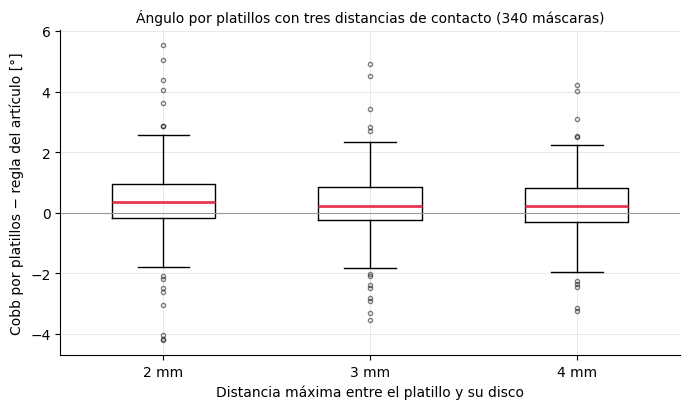

In [ ]:
# 23. Cuánto cambian los platillos y el ángulo por platillos con 2, 3 y 4 mm
por_dist = leer(CSV_PLATILLOS_DIST).drop_duplicates(["serie", "distancia_mm", "vertebra", "platillo"], keep="last")
registro = leer(CSV_REGISTRO_DIST).drop_duplicates("serie", keep="last")
assert set(registro.query("estado == 'ok'")["serie"]) == set(unicas), "Faltan máscaras: vuelve a correr la celda 17"

# Control: con 3 mm deben salir los mismos platillos que en el cuaderno 06
tres = por_dist[por_dist["distancia_mm"] == 3.0].merge(platillos_06, on=["serie", "vertebra", "platillo"], suffixes=("", "_06"))
print(f"Control 3 mm frente al cuaderno 06: {len(tres)} platillos emparejados de {len(platillos_06)}; "
      f"diferencia máxima en el ángulo coronal {(tres['angulo_coronal'] - tres['angulo_coronal_06']).abs().max():.1e}°; "
      f"mismo número de vértices en el {100 * (tres['n_vertices'].fillna(-1) == tres['n_vertices_06'].fillna(-1)).mean():.1f} %")

filas = []
for (s, dist), g in por_dist.groupby(["serie", "distancia_mm"]):
    ang, L, U = cobb_por_platillos(g)
    vecino = g.set_index(["vertebra", "platillo"])["disco_vecino"]
    filas.append({"serie": s, "estudio": estudio_de[s], "distancia_mm": dist, "cobb_platillos": ang,
                  "disco_inf_equivalente": vecino.get((L, "inferior"), np.nan) if not np.isnan(ang) else np.nan,
                  "disco_sup_equivalente": vecino.get((U, "superior"), np.nan) if not np.isnan(ang) else np.nan,
                  "platillos_con_disco": int((~g["excluido_sin_disco"]).sum()),
                  "platillos_sin_plano": int(((~g["excluido_sin_disco"]) & g["angulo_coronal"].isna()).sum())})
cobb_dist = pd.DataFrame(filas)
cobb_dist = cobb_dist.join(reglas[["cobb_articulo", "disco_inf_articulo", "disco_sup_articulo"]], on="serie")
cobb_dist["dif_vs_articulo"] = cobb_dist["cobb_platillos"] - cobb_dist["cobb_articulo"]
cobb_dist["mismo_par_articulo"] = ((cobb_dist["disco_inf_equivalente"] == cobb_dist["disco_inf_articulo"])
                                   & (cobb_dist["disco_sup_equivalente"] == cobb_dist["disco_sup_articulo"]))
tres_mm = cobb_dist[cobb_dist["distancia_mm"] == 3.0].set_index("serie")
print(f"Control 3 mm: diferencia máxima con el ángulo por platillos del cuaderno 06 "
      f"{(tres_mm['cobb_platillos'] - cobb_06.loc[tres_mm.index, 'cobb_platillos']).abs().max():.1e}°")
cobb_dist["dif_vs_3mm"] = cobb_dist["cobb_platillos"] - tres_mm.loc[cobb_dist["serie"], "cobb_platillos"].to_numpy()
cobb_dist.to_csv(DIR_SALIDA / "cobb_platillos_por_distancia.csv", index=False)

# Cada platillo frente a la cara de disco que toca, con cada distancia
pl = por_dist.dropna(subset=["angulo_coronal"]).copy()
pl["disco"] = pl["disco_vecino"].astype(int)
pl["cara"] = np.where(pl["platillo"] == "inferior", "superior", "inferior")
pl = pl.merge(planos_disco[["serie", "disco", "cara", "angulo_coronal_script"]], on=["serie", "disco", "cara"])
pl["dif_platillo_menos_cara"] = pl["angulo_coronal"] - pl["angulo_coronal_script"]
pl["estudio"] = pl["serie"].map(estudio_de)

filas = []
for dist in DISTANCIAS_MM:
    g = cobb_dist[cobb_dist["distancia_mm"] == dist]
    ba = bland_altman(g, "dif_vs_articulo")
    bp = bland_altman(pl[pl["distancia_mm"] == dist], "dif_platillo_menos_cara")
    filas.append({"distancia_mm": dist, "media_cobb_platillos": g["cobb_platillos"].mean(),
                  "platillos_sin_plano": int(g["platillos_sin_plano"].sum()),
                  "sesgo_vs_articulo": ba["sesgo"], "ic95_sesgo": ba["ic95_sesgo"], "lim_inf": ba["lim_inf"],
                  "lim_sup": ba["lim_sup"], "mismo_par_articulo_pct": 100 * g["mismo_par_articulo"].mean(),
                  "mediana_abs_dif_vs_3mm": g["dif_vs_3mm"].abs().median(),
                  "mascaras_mas_de_2_vs_3mm": int((g["dif_vs_3mm"].abs() > 2).sum()),
                  "platillo_vs_cara_lim_inf": bp["lim_inf"], "platillo_vs_cara_lim_sup": bp["lim_sup"]})
resumen_distancia = pd.DataFrame(filas)
resumen_distancia.to_csv(DIR_SALIDA / "resumen_distancia_de_contacto.csv", index=False)
display(resumen_distancia.round(2))
print("Máscaras con el mayor cambio frente a 3 mm:")
print(cobb_dist[cobb_dist["distancia_mm"] != 3.0].assign(orden=lambda d: d["dif_vs_3mm"].abs())
      .sort_values("orden", ascending=False).head(8)[["serie", "distancia_mm", "cobb_platillos", "dif_vs_3mm", "cobb_articulo"]]
      .round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.boxplot([cobb_dist.loc[cobb_dist["distancia_mm"] == d, "dif_vs_articulo"] for d in DISTANCIAS_MM],
           tick_labels=[f"{d:.0f} mm" for d in DISTANCIAS_MM], widths=0.5,
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.axhline(0, color="#999999", lw=0.8)
ax.set_xlabel("Distancia máxima entre el platillo y su disco")
ax.set_ylabel("Cobb por platillos − regla del artículo [°]")
ax.set_title("Ángulo por platillos con tres distancias de contacto (340 máscaras)", fontsize=10)
ejes_limpios(ax)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_distancia_de_contacto.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo interpretar los resultados.** Las dos líneas de control comparan los platillos y el ángulo calculados aquí con 3 mm con los del cuaderno 06. En la tabla, cada fila es una distancia de contacto, y se muestran la media del ángulo por platillos, cuántos platillos se quedaron sin plano por tener menos de 50 puntos cerca del disco, el sesgo frente a la regla del artículo con su intervalo de confianza y sus límites de acuerdo, el porcentaje de máscaras con el mismo par de niveles que la regla del artículo, cuánto cambia el ángulo frente a 3 mm (mediana y número de máscaras con más de 2°) y los límites de acuerdo entre cada platillo y la cara de disco que toca. La gráfica muestra la diferencia con la regla del artículo para cada distancia.

**Resultados.** Con 3 mm, los platillos son prácticamente los del cuaderno 06, con una diferencia máxima de 0,004° en un platillo y el mismo número de puntos en el 99,9 %. Esa pequeña diferencia se debe a que la caja en la que se calculan las distancias ahora es algo mayor, para que alcance para 4 mm, y el ángulo por platillos es idéntico.

Cambiar la distancia casi no mueve los resultados. Con 4 mm, el ángulo medio (8,29°) y el sesgo frente a la regla del artículo (0,26°) son los mismos, y los límites de acuerdo se estrechan un poco (−1,59° a 2,10°). Solo dos máscaras cambian más de 2°, y la mayor es `162_t2_SPACE` (+2,5°). Con 2 mm, el ángulo sube un poco (8,40°), el sesgo pasa a 0,37° (IC del 95 % de 0,22° a 0,52°) y los límites se abren (−1,81° a 2,55°). Además, queda un platillo sin plano, la mediana del cambio frente a 3 mm es de 0,26° y también solo dos máscaras cambian más de 2°. El acuerdo entre cada platillo y la cara de disco que toca apenas cambia, ya que es de ±1,35° con 3 y con 4 mm y de ±1,5° con 2 mm.

En conclusión, los resultados del cuaderno 06 son poco sensibles al umbral de contacto. Con 4 mm se mantienen prácticamente iguales, y con 2 mm empeoran ligeramente porque cada platillo se ajusta con menos puntos. Por ello, se conserva el umbral de 3 mm.

## Lo que SPIDER no permite responder

Hay preguntas planteadas en los cuadernos anteriores que estos datos no permiten resolver. Conviene dejarlas explícitas para evitar interpretarlas como conclusiones ya establecidas.

- **La exactitud clínica de cualquiera de las medidas.** SPIDER no incluye ángulos de Cobb medidos por especialistas, así que ninguna de las comparaciones de este proyecto dice cuál medida se acerca más a la curva real. Solo dicen cuánto cambia la salida del algoritmo.
- **La generalización a otros centros.** Todas las máscaras vienen de cuatro hospitales de un mismo país, y los dos segmentadores usaron datos de SPIDER. Lo aborda el cuaderno 08 con otros datasets.
- **El grosor de corte en adquisiciones reales.** El cuaderno 04 simuló cortes gruesos sobre la máscara, no sobre la imagen, y con máscaras finas de un solo centro.
- **La posición del paciente.** Las RM son en decúbito, mientras que el Cobb clínico suele medirse de pie, y los autores señalan que el ángulo de pie suele ser mayor.
- **La curva fuera del campo de visión.** Si la curva sigue por encima de la última vértebra visible, ninguna regla puede medirla completa (ver la sección del disco más craneal).
- **La reproducibilidad del segmentador en otro entorno.** Las 447 máscaras de SPIDER-Baseline-IIS salieron de un solo entorno de ejecución, con GPU. Comparar con otro entorno requiere GPU y queda pendiente, aunque entre ellas las máscaras son comparables.
- **El registro de 23 series de TotalSpineSeg.** Su registro de ejecución no se conservó (cuaderno 05). Sus máscaras se usaron, pero no se puede documentar su tiempo ni sus versiones exactas.

## Síntesis

**Los centros.** En SPIDER, el escáner permite inferir el hospital de cada estudio, porque de las 6561 formas de repartir los grupos de escáner solo una reproduce la Tabla 1 del artículo, y el porcentaje de mujeres queda a un paciente o menos en los cuatro hospitales. El hospital inferido puede reemplazar al indicador aproximado del cuaderno 01.

**Cuántos niveles.** El ángulo se conserva mientras la máscara tenga al menos seis discos. Con menos, casi siempre baja, y con tres o cuatro cambia más de 2° en más de un tercio de las máscaras. La gran diferencia del estudio 35 que encontró el cuaderno 02 venía sobre todo de la regla del script, ya que con la regla del artículo es de 1,9°.

**La regla correcta.** La diferencia entre la regla del script y la del artículo se debe solo al orden en que se recorren los discos, ya que con la numeración de SPIDER-Baseline-IIS la regla del script es exactamente la del artículo, como explicó Jasper van der Graaf. Corrido sin cambios sobre SPIDER, el script infla el ángulo en promedio 0,39°, lo cambia más de 2° en 40 máscaras y más de 5° en cuatro, entre ellas las dos del estudio 162. A partir de este cuaderno, el ángulo de referencia del proyecto se calcula con la regla del artículo.

**Evitar el disco 201.** Quitar esa cara corrige de más, porque baja el ángulo por debajo de la regla del artículo y de los platillos al eliminar también la cara correcta del mismo disco. El emparejamiento previsto es la corrección adecuada.

**La fórmula.** Se probaron cinco candidatas frente al borde de los discos en la proyección coronal, con discos sintéticos, con más de mil discos reales rotados y en las máscaras de SPIDER. Entre las fórmulas de la normal, el eje lateral proyectado es la más cercana al borde proyectado y la más reproducible entre segmentaciones. La proyección directa y la regla por tramos parecen mejores en el banco, pero solo porque miden lo mismo que la referencia, y en datos reales son mucho más ruidosas. Por eso, desde el cuaderno 08 la principal es el eje lateral, con $\arctan(n_x/n_z)$ a su lado como referencia del método publicado.

**El extremo craneal.** El corte por el campo de visión no explica por qué el disco más craneal aparece tan a menudo en el par, ya que con la regla del artículo solo en dos máscaras se usa un disco cortado. Una explicación compatible con los datos es que, en las curvas más grandes, la vértebra límite craneal está en el borde del campo de visión o por encima, de modo que el ángulo lumbar podría quedarse corto frente a la curva completa.

**El grosor de corte.** Con la regla del artículo, el efecto del grosor se mantiene casi igual (−0,25° con 3,3 mm y −0,38° con 4,4 mm), y el acuerdo entre la T2 SPACE y la serie estándar mejora. Su sesgo, de −0,50°, va en el sentido que predice el grosor.

**Entrenamiento frente a validación.** Dentro de SPIDER no aparece una ventaja de SPIDER-Baseline-IIS en las series con las que se entrenó, pero eso no reemplaza una prueba en datos externos.

**La dirección de la inclinación.** En una cara inclinada unos 45°, como la superior del disco 201 en las columnas lordóticas, el ángulo coronal cambia casi grado por grado con la dirección de la inclinación en el plano axial. Eso explica el estudio 65, tanto entre segmentadores como entre la cara del disco y el platillo, y se repite en las pocas columnas que combinan mucha inclinación con una diferencia de dirección de varios grados.

**La distancia de contacto.** Los resultados del cuaderno 06 son poco sensibles al umbral, ya que con 4 mm son prácticamente iguales y con 2 mm empeoran un poco (sesgo de 0,37° frente a 0,26°), así que se mantienen los 3 mm.

In [ ]:
# 24. LEEME.md de la carpeta de resultados
leeme = f"""# 07 · La regla correcta y las preguntas pendientes

Resultados de `notebooks/07_regla_del_articulo_y_preguntas_pendientes.ipynb`. Solo investigación; no es para diagnóstico.
Cierra las preguntas abiertas de los cuadernos 01 a 06 con sus resultados y con las {N_UNICAS} máscaras manuales únicas de SPIDER v4; no se vuelve a correr el script.

| Archivo | Qué contiene |
|-|-|
| `centros_frente_a_tabla1.csv`, `hospital_inferido_por_serie.csv` | Grupos de escáner frente a la Tabla 1 del artículo de SPIDER y hospital inferido para cada serie |
| `recorte_de_niveles.csv`, `resumen_recorte_de_niveles.csv`, `parejas_por_cobertura.csv`, `figura_recorte_de_niveles.png` | El ángulo según cuántos discos entran en la máscara |
| `reglas_por_mascara.csv` | Ángulo y par de discos con la regla del script, la del artículo, la del script recorriendo los discos de arriba hacia abajo y la del artículo con arcsen(nx) |
| `script_frente_a_articulo.csv`, `figura_script_frente_a_articulo.png` | Cuánto cambia el ángulo al pasar de la regla del script a la del artículo |
| `variantes_frente_a_articulo.csv`, `resumen_variantes_frente_a_articulo.csv`, `figura_variantes_frente_a_articulo.png` | Variantes A, B y AB del cuaderno 03, regla del artículo y platillos del cuaderno 06 |
| `banco_formula_desarrollo.csv`, `banco_formula_prueba.csv`, `resumen_banco_formula.csv`, `figura_banco_formula.png` | Banco de pruebas de la fórmula: cinco candidatas frente al borde proyectado, en discos sintéticos y en discos reales rotados |
| `proyeccion_por_disco_manual.csv`, `proyeccion_por_disco_tss.csv`, `proyeccion_por_disco_iis.csv` | Ángulo del borde superior e inferior de cada disco en la proyección coronal, en las máscaras manuales y automáticas |
| `cobb_por_candidata_manual.csv`, `cobb_por_candidata_tss.csv`, `cobb_por_candidata_iis.csv`, `reproducibilidad_por_candidata.csv`, `figura_reproducibilidad_por_candidata.png` | Ángulo de Cobb (regla del artículo) con cada candidata y su reproducibilidad entre segmentaciones |
| `cobertura_por_disco.csv` | Para cada disco, si toca el borde craneal, caudal o lateral de la imagen |
| `extremo_craneal_por_mascara.csv`, `resumen_extremo_craneal.csv`, `panel_extremo_craneal.png` | Uso del disco más craneal por cada regla, si está cortado y cuánto cambia el ángulo sin él |
| `grosor_con_regla_del_articulo.csv`, `resumen_grosor_con_regla_del_articulo.csv`, `space_frente_a_estandar_con_regla_del_articulo.csv`, `resumen_space_frente_a_estandar.csv` | Las cifras del cuaderno 04 con la regla del artículo |
| `entrenamiento_frente_a_validacion.csv`, `figura_entrenamiento_frente_a_validacion.png` | Acuerdo de cada segmentador con la máscara manual en las particiones de SPIDER |
| `direccion_manual_frente_a_automatica.csv`, `resumen_direccion_por_inclinacion.csv`, `direccion_platillo_frente_a_cara.csv`, `estudio_65_por_superficie.csv`, `figura_direccion_extremo_caudal.png` | Inclinación total y dirección de cada cara: máscaras automáticas, platillos y el estudio 65 |
| `platillos_por_distancia.csv`, `registro_platillos_por_distancia.csv`, `cobb_platillos_por_distancia.csv`, `resumen_distancia_de_contacto.csv`, `figura_distancia_de_contacto.png` | Platillos y ángulo por platillos con 2, 3 y 4 mm de distancia de contacto |
| `entorno.json` | Versiones, commits, huellas y parámetros |

Regla del script: max |cara inferior del disco de abajo − cara superior del de arriba|; regla del artículo: max |cara superior del disco de abajo − cara inferior del de arriba|; discos numerados de caudal a craneal.
Disco cortado: toca el borde craneal o el primer o último corte sagital de la imagen reorientada. Inclinación total y dirección: tan(arctan(nx/nz)) = tan(i) · sen(a).
Bootstrap de {B_BOOTSTRAP} repeticiones por estudio, semilla {SEMILLA}.
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 07 · La regla correcta y las preguntas pendientes

Resultados de `notebooks/07_regla_del_articulo_y_preguntas_pendientes.ipynb`. Solo investigación; no es para diagnóstico.
Cierra las preguntas abiertas de los cuadernos 01 a 06 con sus resultados y con las 340 máscaras manuales únicas de SPIDER v4; no se vuelve a correr el script.

| Archivo | Qué contiene |
|-|-|
| `centros_frente_a_tabla1.csv`, `hospital_inferido_por_serie.csv` | Grupos de escáner frente a la Tabla 1 del artículo de SPIDER y hospital inferido para cada serie |
| `recorte_de_niveles.csv`, `resumen_recorte_de_niveles.csv`, `parejas_por_cobertura.csv`, `figura_recorte_de_niveles.png` | El ángulo según cuántos discos entran en la máscara |
| `reglas_por_mascara.csv` | Ángulo y par de discos con la regla del script, la del artículo, la del script recorriendo los discos de arriba hacia abajo y la del artículo con arcsen(nx) |
| `script_frente_a_articulo.csv`, `figura_script_frente_a_articulo.png` | Cuánto cambia el ángul

In [ ]:
# 25. Registro del entorno (para docs/fuentes_externas.md y para reproducir la corrida)
import json, sys, platform, datetime, importlib.metadata as md_
def version_de(paquete):
    try:
        return md_.version(paquete)
    except md_.PackageNotFoundError:
        return None
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "matplotlib", "scipy", "scikit-image", "tiger")},
    "tiger_commit": COMMIT_TIGER, "masks_zip_md5": MD5_MASKS_ZIP,
    "entradas": {"inventario": "inventario_series.csv del cuaderno 01",
                 "caras_de_disco": "planos_por_disco.csv del cuaderno 03", "script_commit": COMMIT_SCRIPT,
                 "variantes": "angulos_variantes.csv del cuaderno 03",
                 "grosor": "planos_engrosamiento.csv y bland_altman_comparaciones.csv del cuaderno 04",
                 "segmentacion_automatica": "comparacion_por_serie.csv y planos_por_disco_iis/tss.csv del cuaderno 05",
                 "platillos": "cobb_por_serie.csv y platillos_por_vertebra.csv del cuaderno 06"},
    "tabla_1_spider": TABLA_1.to_dict(orient="index"),
    "reglas": {"script": "max |inf(a) − sup(b)|, a < b, discos de caudal a craneal",
               "articulo": "max |sup(a) − inf(b)|, a < b, discos de caudal a craneal",
               "script_invertido": "max |inf(a) − sup(b)|, a antes que b, discos de craneal a caudal"},
    "disco_cortado": "toca el borde craneal o el primer o último corte sagital de la máscara reorientada con Tiger",
    "banco_formula": {"formas_sinteticas_mm": FORMAS_SINTETICAS, "inclinaciones_desarrollo": INCL_DESARROLLO,
                      "direcciones_desarrollo": DIREC_DESARROLLO, "discos_reales_prueba": N_DISCOS_PRUEBA,
                      "inclinaciones_prueba": INCL_PRUEBA, "direcciones_prueba": DIREC_PRUEBA,
                      "grosor_simulado_mm": GROSOR_SIMULADO_MM, "regla_por_tramos": REGLA_TRAMOS,
                      "referencia": "recta del borde en la proyección coronal de la máscara fina, 60 % central del ancho"},
    "platillos": {"distancias_mm": list(DISTANCIAS_MM), "angulo_max_grados": ANGULO_MAX_PLATILLO,
                  "min_vertices": MIN_VERTICES},
    "bootstrap": {"repeticiones": B_BOOTSTRAP, "semilla": SEMILLA, "unidad": "estudio"},
    "n_mascaras_unicas": len(unicas),
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(entorno, indent=2, ensure_ascii=False, default=str))

{
  "fecha": "2026-10-29T08:51:18",
  "python": "3.13.18",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "paquetes": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "scipy": "1.16.3",
    "scikit-image": "0.25.2",
    "tiger": "6.3.0"
  },
  "tiger_commit": "4c63f6d58ed3f8e7a0cec04b0352949f7b512919",
  "masks_zip_md5": "49861ff25a0108b3b69d0ce808ae51dc",
  "entradas": {
    "inventario": "inventario_series.csv del cuaderno 01",
    "caras_de_disco": "planos_por_disco.csv del cuaderno 03",
    "script_commit": "72c712f31e1f3069aef77b98b20af448bbc5615a",
    "variantes": "angulos_variantes.csv del cuaderno 03",
    "grosor": "planos_engrosamiento.csv y bland_altman_comparaciones.csv del cuaderno 04",
    "segmentacion_automatica": "comparacion_por_serie.csv y planos_por_disco_iis/tss.csv del cuaderno 05",
    "platillos": "cobb_por_serie.csv y platillos_por_vertebra.csv del cuaderno 06"
  },
  "tabla_1_spider": {
    "UMC": {
      "estudios": 4